
<div style="background:linear-gradient(135deg,#0F2044 0%,#1A4A8A 55%,#2E86DE 100%);
            padding:55px 45px;border-radius:14px;color:white;">
  <h1 style="font-size:2.6em;margin:0 0 8px 0;color:#0DC0C0;letter-spacing:3px;">
    🧹 PRÉTRAITEMENT DES IMAGES
  </h1>
  <h2 style="font-size:1.4em;font-weight:300;margin:0 0 6px 0;color:white;">
    Travaux Pratiques approfondis — M2 Informatique / Vision par Ordinateur
  </h2>
  <p style="color:#B0C4DE;font-size:0.95em;margin:0 0 28px 0;font-style:italic;">
    Nettoyage · Normalisation · Transformations géométriques · Data Augmentation · Pipelines
  </p>
  <hr style="border-color:#2E86DE55;margin:0 0 22px 0;">
  <p style="color:#E8ECF4;line-height:1.9;margin:0 0 22px 0;font-size:1.05em;">
    Ce TP couvre <strong style="color:#0DC0C0;">l'intégralité du pipeline de prétraitement</strong> en vision
    par ordinateur, de la lecture brute d'une image jusqu'aux techniques avancées d'augmentation de données
    utilisées en production. Chaque section combine rappels théoriques, démonstrations et exercices progressifs.
  </p>
  <div style="display:grid;grid-template-columns:repeat(4,1fr);gap:12px;">
    <div style="background:#ffffff18;border-radius:8px;padding:10px 14px;border-left:3px solid #0DC0C0;">
      <div style="font-size:1.4em;">📚</div>
      <div style="font-size:0.85em;font-weight:bold;color:#0DC0C0;">7 Modules</div>
      <div style="font-size:0.8em;color:#B0C4DE;">de théorie</div>
    </div>
    <div style="background:#ffffff18;border-radius:8px;padding:10px 14px;border-left:3px solid #F97316;">
      <div style="font-size:1.4em;">🏋️</div>
      <div style="font-size:0.85em;font-weight:bold;color:#F97316;">14 Exercices</div>
      <div style="font-size:0.8em;color:#B0C4DE;">guidés avec hints</div>
    </div>
    <div style="background:#ffffff18;border-radius:8px;padding:10px 14px;border-left:3px solid #22C55E;">
      <div style="font-size:1.4em;">🔬</div>
      <div style="font-size:0.85em;font-weight:bold;color:#22C55E;">Demos visuelles</div>
      <div style="font-size:0.8em;color:#B0C4DE;">NumPy · OpenCV · PIL</div>
    </div>
    <div style="background:#ffffff18;border-radius:8px;padding:10px 14px;border-left:3px solid #9B59B6;">
      <div style="font-size:1.4em;">🏆</div>
      <div style="font-size:0.85em;font-weight:bold;color:#9B59B6;">Projet final</div>
      <div style="font-size:0.8em;color:#B0C4DE;">pipeline complet</div>
    </div>
  </div>
</div>


---
## ⚙️ Installation & Configuration

Exécutez cette cellule en premier — elle installe les dépendances et configure l'environnement.

✅  Environnement prêt !
   Images de test : (256, 256, 3)  dtype=uint8
   Librairies     : NumPy 2.4.3  |  OpenCV 4.13.0


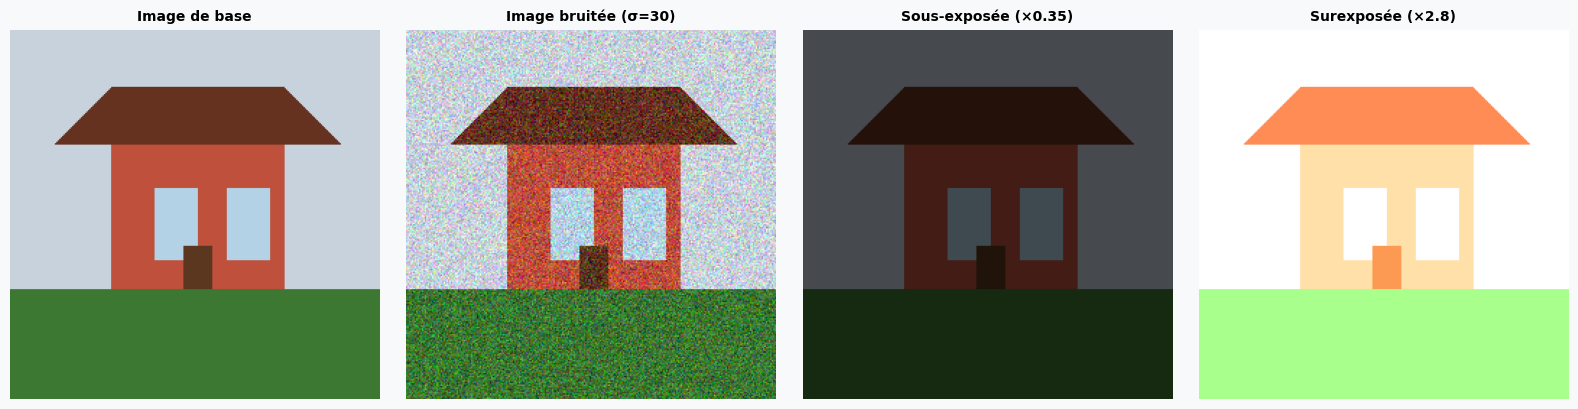

In [1]:
# ── Installation (décommentez si nécessaire) ──────────────────
# !pip install numpy matplotlib opencv-python pillow scikit-image

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from PIL import Image, ImageFilter, ImageEnhance, ImageOps
import cv2
from skimage import io, filters, exposure, transform, util, color
from skimage import morphology, restoration
import warnings
warnings.filterwarnings("ignore")

# ── Configuration matplotlib ──────────────────────────────────
plt.rcParams.update({
    "figure.facecolor": "#F8F9FA",
    "axes.facecolor":   "#FFFFFF",
    "axes.spines.top":  False,
    "axes.spines.right":False,
    "font.family":      "DejaVu Sans",
    "axes.titlesize":   12,
    "axes.titleweight": "bold",
    "figure.dpi":       100,
})

# ── Palette de couleurs du TP ─────────────────────────────────
NAVY   = "#0F2044"
BLUE   = "#2E86DE"
TEAL   = "#0DC0C0"
ORANGE = "#F97316"
GREEN  = "#22C55E"
RED    = "#E74C3C"
PURPLE = "#9B59B6"

# ── Fonction utilitaire : afficher une grille d'images ────────
def show_grid(images, titles, ncols=4, figsize=None, cmap_default="gray"):
    nrows = (len(images) + ncols - 1) // ncols
    if figsize is None:
        figsize = (4 * ncols, 3.5 * nrows)
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    axes = np.array(axes).ravel()
    for ax, img, title in zip(axes, images, titles):
        cmap = None if (len(np.array(img).shape) == 3 and np.array(img).shape[2] == 3) else cmap_default
        ax.imshow(np.array(img), cmap=cmap, vmin=0 if cmap else None, vmax=255 if cmap else None)
        ax.set_title(title, fontsize=10, pad=6)
        ax.axis("off")
    for ax in axes[len(images):]:
        ax.set_visible(False)
    plt.tight_layout()
    plt.show()

# ── Génération des images de test synthétiques ────────────────
np.random.seed(42)
H, W = 256, 256

def make_base_image():
    img = np.zeros((H, W, 3), dtype=np.uint8)
    img[:, :]          = [200, 210, 220]   # fond gris-bleu
    img[180:, :]       = [60, 120, 50]     # sol vert
    img[80:180, 70:190]= [190, 80, 60]     # bâtiment rouge
    for i in range(40):                     # toit triangulaire
        s = max(0, 70 - i); e = min(W, 190 + i)
        img[40+i, s:e] = [100, 50, 30]
    img[110:160, 100:130] = [180, 210, 230] # fenêtre gauche
    img[110:160, 150:180] = [180, 210, 230] # fenêtre droite
    img[150:180, 120:140] = [90, 55, 30]   # porte
    return img

def make_noisy_image(img, sigma=25):
    noise = np.random.randn(*img.shape) * sigma
    return np.clip(img.astype(np.float32) + noise, 0, 255).astype(np.uint8)

def make_dark_image(img, factor=0.35):
    return np.clip(img.astype(np.float32) * factor, 0, 255).astype(np.uint8)

def make_overexposed_image(img, factor=2.8):
    return np.clip(img.astype(np.float32) * factor, 0, 255).astype(np.uint8)

BASE_IMG   = make_base_image()
NOISY_IMG  = make_noisy_image(BASE_IMG, sigma=30)
DARK_IMG   = make_dark_image(BASE_IMG)
BRIGHT_IMG = make_overexposed_image(BASE_IMG)

print("✅  Environnement prêt !")
print(f"   Images de test : {BASE_IMG.shape}  dtype={BASE_IMG.dtype}")
print(f"   Librairies     : NumPy {np.__version__}  |  OpenCV {cv2.__version__}")

# Aperçu des images de test
show_grid(
    [BASE_IMG, NOISY_IMG, DARK_IMG, BRIGHT_IMG],
    ["Image de base", "Image bruitée (σ=30)", "Sous-exposée (×0.35)", "Surexposée (×2.8)"],
    ncols=4, figsize=(16, 4)
)



---
<div style="background:linear-gradient(90deg,#0F2044,#1A4A8A);padding:20px 28px;border-radius:10px;border-left:7px solid #0DC0C0;">
  <h1 style="color:#0DC0C0;margin:0;font-size:1.65em;">📦 Module 1 — Représentation numérique & espaces colorimétriques</h1>
  <p style="color:#B0C4DE;margin:6px 0 0 0;">Comprendre comment une image est stockée en mémoire</p>
</div>



### 📖 Rappel théorique

#### Structure mémoire d'une image

| Format | Shape NumPy | Valeurs | Usage |
|--------|-------------|---------|-------|
| Niveaux de gris | `(H, W)` | 0–255 (uint8) | Médical, documents |
| RGB | `(H, W, 3)` | R, G, B ∈ [0,255] | Photos, écrans |
| RGBA | `(H, W, 4)` | RGB + Alpha | Images avec transparence |
| float32 | `(H, W, C)` | [0.0, 1.0] | Entrée des CNN |

#### Espaces colorimétriques courants

```
RGB  → canaux R, G, B corrélés, non-uniforme perceptuellement
HSV  → Hue (teinte), Saturation, Value (luminosité) — intuitif pour la couleur
LAB  → L (luminosité), a (rouge-vert), b (bleu-jaune) — perceptuellement uniforme
YCrCb→ Luminance Y + chrominances Cr, Cb — utilisé en vidéo/JPEG
```

#### Pourquoi changer d'espace colorimétrique ?
- **HSV** : sélection de couleur par teinte (insensible à la luminosité)
- **LAB** : métriques de distance perceptuelle (ΔE), transfert de couleur
- **Niveaux de gris** : réduire la dimensionnalité (1 canal au lieu de 3)

> 💡 **Formule luminance perceptuelle** (ITU-R BT.709) :  
> `L = 0.2126 × R + 0.7152 × G + 0.0722 × B`


### 🔬 Démonstration — Espaces colorimétriques

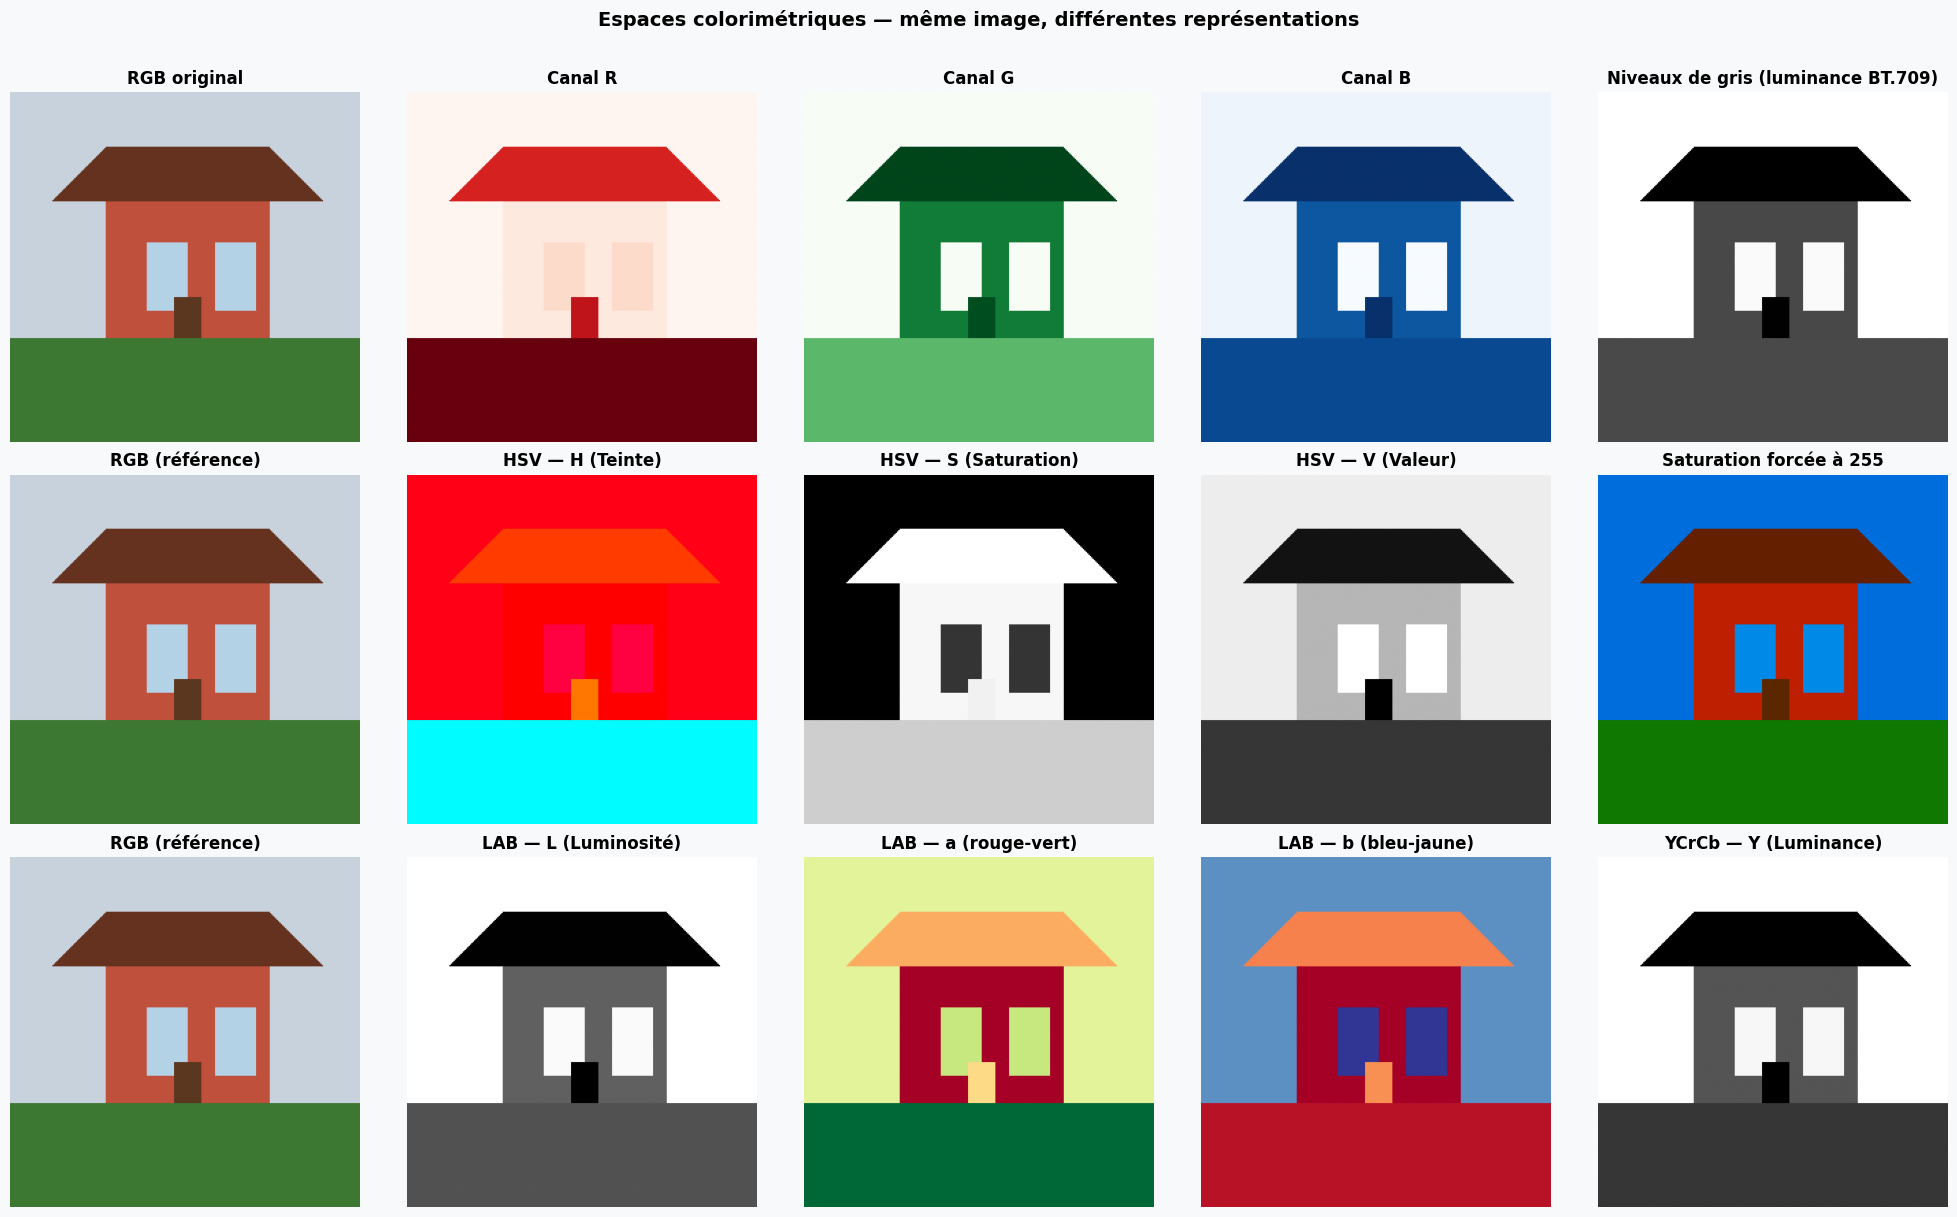

Canal                   Min    Max      Moy   Écart-type
R (RGB)                60.0  200.0   145.54        62.97
G (RGB)                50.0  210.0   149.47        60.31
B (RGB)                30.0  230.0   129.04        86.40
H (HSV)                 5.0  105.0    67.19        39.40
S (HSV)                23.0  179.0    97.89        68.31
L (LAB)                68.0  214.0   157.27        54.78


In [2]:
img = BASE_IMG.copy()

# ── Conversions vers différents espaces ───────────────────────
gray_mean   = np.mean(img, axis=2).astype(np.uint8)
gray_percep = (0.2126 * img[:,:,0] + 0.7152 * img[:,:,1] + 0.0722 * img[:,:,2]).astype(np.uint8)
img_hsv     = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
img_lab     = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
img_ycrcb   = cv2.cvtColor(img, cv2.COLOR_RGB2YCrCb)

fig, axes = plt.subplots(3, 5, figsize=(20, 12))

# Ligne 1 : RGB et canaux
axes[0,0].imshow(img);  axes[0,0].set_title("RGB original")
axes[0,1].imshow(img[:,:,0], cmap="Reds_r");  axes[0,1].set_title("Canal R")
axes[0,2].imshow(img[:,:,1], cmap="Greens_r"); axes[0,2].set_title("Canal G")
axes[0,3].imshow(img[:,:,2], cmap="Blues_r");  axes[0,3].set_title("Canal B")
axes[0,4].imshow(gray_percep, cmap="gray")
axes[0,4].set_title("Niveaux de gris (luminance BT.709)")

# Ligne 2 : HSV
axes[1,0].imshow(img); axes[1,0].set_title("RGB (référence)")
axes[1,1].imshow(img_hsv[:,:,0], cmap="hsv");  axes[1,1].set_title("HSV — H (Teinte)")
axes[1,2].imshow(img_hsv[:,:,1], cmap="gray"); axes[1,2].set_title("HSV — S (Saturation)")
axes[1,3].imshow(img_hsv[:,:,2], cmap="gray"); axes[1,3].set_title("HSV — V (Valeur)")
# Reconstitution d'une image avec saturation maximale
hsv_sat = img_hsv.copy(); hsv_sat[:,:,1] = 255
axes[1,4].imshow(cv2.cvtColor(hsv_sat, cv2.COLOR_HSV2RGB))
axes[1,4].set_title("Saturation forcée à 255")

# Ligne 3 : LAB
axes[2,0].imshow(img); axes[2,0].set_title("RGB (référence)")
axes[2,1].imshow(img_lab[:,:,0], cmap="gray"); axes[2,1].set_title("LAB — L (Luminosité)")
axes[2,2].imshow(img_lab[:,:,1], cmap="RdYlGn_r"); axes[2,2].set_title("LAB — a (rouge-vert)")
axes[2,3].imshow(img_lab[:,:,2], cmap="RdYlBu_r"); axes[2,3].set_title("LAB — b (bleu-jaune)")
axes[2,4].imshow(img_ycrcb[:,:,0], cmap="gray"); axes[2,4].set_title("YCrCb — Y (Luminance)")

for ax in axes.ravel():
    ax.axis("off")

plt.suptitle("Espaces colorimétriques — même image, différentes représentations",
             fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

# Statistiques par canal
print("=" * 60)
print(f"{'Canal':<20} {'Min':>6} {'Max':>6} {'Moy':>8} {'Écart-type':>12}")
print("=" * 60)
for name, ch in [("R (RGB)", img[:,:,0]), ("G (RGB)", img[:,:,1]),
                  ("B (RGB)", img[:,:,2]), ("H (HSV)", img_hsv[:,:,0]),
                  ("S (HSV)", img_hsv[:,:,1]), ("L (LAB)", img_lab[:,:,0])]:
    print(f"{name:<20} {ch.min():>6.1f} {ch.max():>6.1f} {ch.mean():>8.2f} {ch.std():>12.2f}")



---
### 🏋️ Exercice 1 — Sélection de couleur par masque HSV

**Contexte :** En robotique et en vision industrielle, on veut souvent isoler des objets par leur couleur (ex : détecter un fruit rouge sur une table).

**Objectif :** Dans `BASE_IMG`, isoler les zones **rouges** (le bâtiment) en utilisant l'espace HSV, puis afficher :
1. Le masque binaire de la sélection
2. L'image originale avec la zone rouge mise en évidence (fond grisé)
3. L'histogramme du canal H dans la zone sélectionnée

<details>
<summary>💡 <strong>Hints</strong></summary>

**Hint 1 — Convertir en HSV :**
```python
img_hsv = cv2.cvtColor(BASE_IMG, cv2.COLOR_RGB2HSV)
# En OpenCV HSV : H ∈ [0,179], S ∈ [0,255], V ∈ [0,255]
```
**Hint 2 — Plage HSV du rouge :** Le rouge est autour de H=0 et H=179 (enroulement circulaire).
```python
lower1 = np.array([0,   80, 60])   # rouge bas (H ~0°)
upper1 = np.array([10, 255, 255])
lower2 = np.array([165, 80, 60])   # rouge haut (H ~330°)
upper2 = np.array([179, 255, 255])
mask1 = cv2.inRange(img_hsv, lower1, upper1)
mask2 = cv2.inRange(img_hsv, lower2, upper2)
mask  = cv2.bitwise_or(mask1, mask2)   # shape (H, W), valeurs 0 ou 255
```
**Hint 3 — Appliquer le masque sur l'image originale :**
```python
result = BASE_IMG.copy()
result[mask == 0] = (np.mean(BASE_IMG, axis=2, keepdims=True) * [0.5,0.5,0.5]).astype(np.uint8)[mask==0]
# Ou plus simplement : mettre le fond en gris
gray3  = np.stack([gray_percep]*3, axis=2)
result = np.where(mask[:,:,np.newaxis] > 0, BASE_IMG, gray3 // 2)
```
</details>


EXERCICE 1 — Sélection de couleur par masque HSV


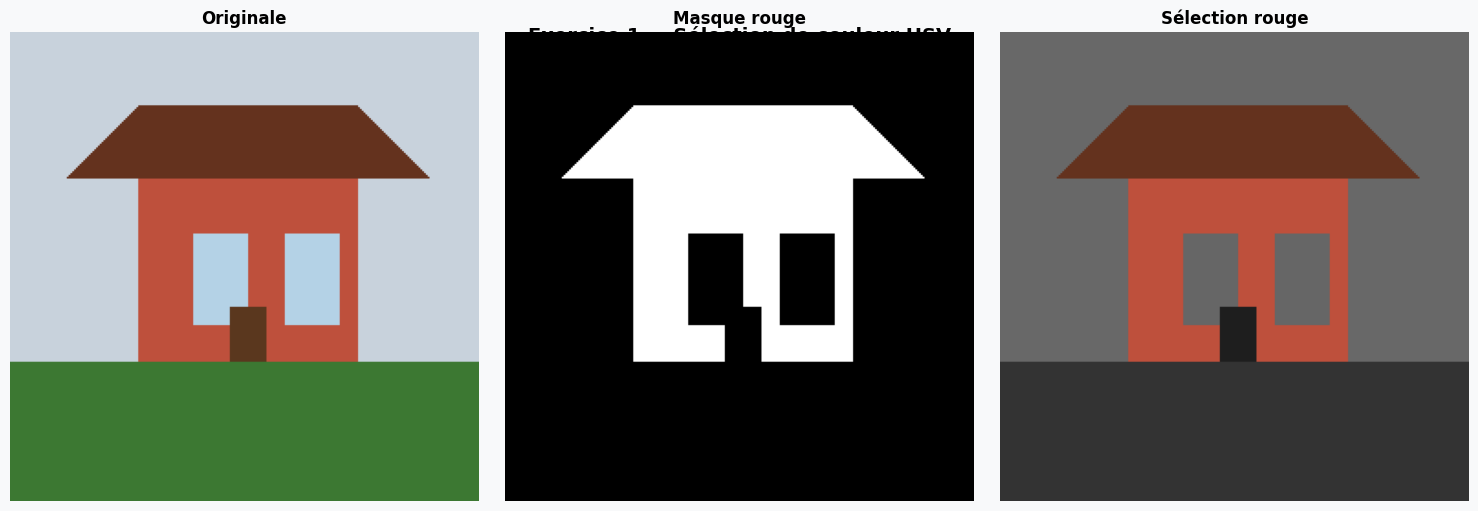

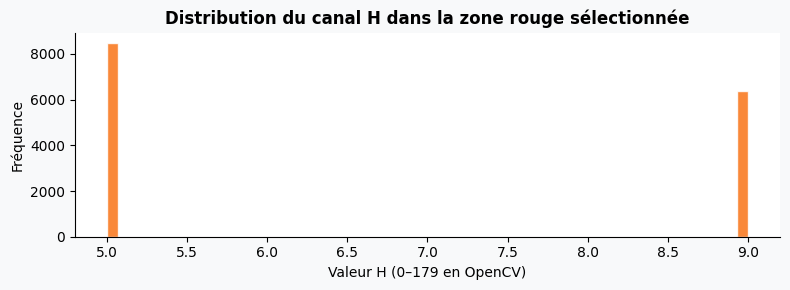

In [8]:
# ── Exercice 1 — 
print("=" * 60)
print("EXERCICE 1 — Sélection de couleur par masque HSV")
print("=" * 60)

# 1. Convertir BASE_IMG en HSV
img_hsv_ex1 = cv2.cvtColor(BASE_IMG, cv2.COLOR_RGB2HSV)

# 2. Créer le masque rouge (deux plages HSV)
lower1 = np.array([0,   80, 60])
upper1 = np.array([10, 255, 255])
lower2 = np.array([165, 80, 60])
upper2 = np.array([179, 255, 255])
mask1 = cv2.inRange(img_hsv_ex1, lower1, upper1)
mask2 = cv2.inRange(img_hsv_ex1, lower2, upper2)
mask_rouge = cv2.bitwise_or(mask1, mask2)

# 3. Appliquer le masque : fond grisé, zones rouges en couleur
gray_percep = (0.2126 * BASE_IMG[:,:,0] + 0.7152 * BASE_IMG[:,:,1] + 0.0722 * BASE_IMG[:,:,2]).astype(np.uint8)
gray3 = np.stack([gray_percep]*3, axis=2)
result = np.where(mask_rouge[:,:,np.newaxis] > 0, BASE_IMG, gray3 // 2)

# 4. Afficher : image originale | masque binaire | résultat
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(BASE_IMG);           axes[0].set_title("Originale"); axes[0].axis("off")
axes[1].imshow(mask_rouge, cmap="gray"); axes[1].set_title("Masque rouge"); axes[1].axis("off")
axes[2].imshow(result);             axes[2].set_title("Sélection rouge"); axes[2].axis("off")
plt.tight_layout()
plt.suptitle("Exercice 1 — Sélection de couleur HSV", fontsize=14, fontweight="bold")
plt.show()

# 5. Histogramme H dans la zone sélectionnée
h_vals = img_hsv_ex1[:,:,0][mask_rouge > 0]
plt.figure(figsize=(8, 3))
plt.hist(h_vals, bins=60, color=ORANGE, edgecolor="white", alpha=0.85)
plt.title("Distribution du canal H dans la zone rouge sélectionnée")
plt.xlabel("Valeur H (0–179 en OpenCV)")
plt.ylabel("Fréquence")
plt.tight_layout()
plt.show()



<details>
<summary>✅ <strong>Correction complète</strong></summary>

```python
img_hsv_ex1 = cv2.cvtColor(BASE_IMG, cv2.COLOR_RGB2HSV)

lower1 = np.array([0,   80, 60]); upper1 = np.array([10, 255, 255])
lower2 = np.array([165, 80, 60]); upper2 = np.array([179, 255, 255])
mask_rouge = cv2.bitwise_or(cv2.inRange(img_hsv_ex1, lower1, upper1),
                             cv2.inRange(img_hsv_ex1, lower2, upper2))

gray3  = np.stack([(0.2126*BASE_IMG[:,:,0]+0.7152*BASE_IMG[:,:,1]+0.0722*BASE_IMG[:,:,2]).astype(np.uint8)]*3, axis=2)
result = np.where(mask_rouge[:,:,np.newaxis] > 0, BASE_IMG, gray3 // 2)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(BASE_IMG);            axes[0].set_title("Originale"); axes[0].axis("off")
axes[1].imshow(mask_rouge, cmap="gray"); axes[1].set_title("Masque"); axes[1].axis("off")
axes[2].imshow(result);              axes[2].set_title("Sélection"); axes[2].axis("off")
plt.tight_layout(); plt.show()
```
</details>



---
<div style="background:linear-gradient(90deg,#0F2044,#1A4A8A);padding:20px 28px;border-radius:10px;border-left:7px solid #2E86DE;">
  <h1 style="color:#2E86DE;margin:0;font-size:1.65em;">⚖️ Module 2 — Normalisation & ajustement d'intensité</h1>
  <p style="color:#B0C4DE;margin:6px 0 0 0;">Corriger l'exposition, uniformiser les distributions de pixels</p>
</div>



### 📖 Rappel théorique

#### Pourquoi normaliser ?

Les CNN sont sensibles à l'échelle des valeurs d'entrée. Une image sous-exposée (plage 0–80) et une surexposée (plage 150–255) représentent le même contenu mais avec des distributions très différentes — le réseau les traite comme des images totalement distinctes.

#### Techniques de normalisation

| Technique | Formule | Usage |
|-----------|---------|-------|
| **Min-max** | $x' = (x - x_{min}) / (x_{max} - x_{min})$ | Ramener dans [0, 1] |
| **Z-score** | $x' = (x - \mu) / \sigma$ | Centrer-réduire (ImageNet : μ, σ par canal) |
| **Étalement d'histogramme** | Remap linéaire [p2, p98] → [0, 255] | Robuste aux outliers |
| **Égalisation d'histogramme** | CDF uniforme | Rehausser le contraste global |
| **CLAHE** | Égalisation adaptative par tuiles | Contraste local, sans sur-amplifier |

#### Normalisation ImageNet (très utilisée en Transfer Learning)

```python
mean = [0.485, 0.456, 0.406]   # par canal R, G, B
std  = [0.229, 0.224, 0.225]
img_norm = (img_float - mean) / std
```

#### Égalisation d'histogramme — principe

L'histogramme cumulé (CDF) est remappé pour être linéaire :  
$$x'= \frac{CDF(x) - CDF_{min}}{(H \times W) - CDF_{min}} \times 255$$


### 🔬 Démonstration — Techniques de normalisation comparées

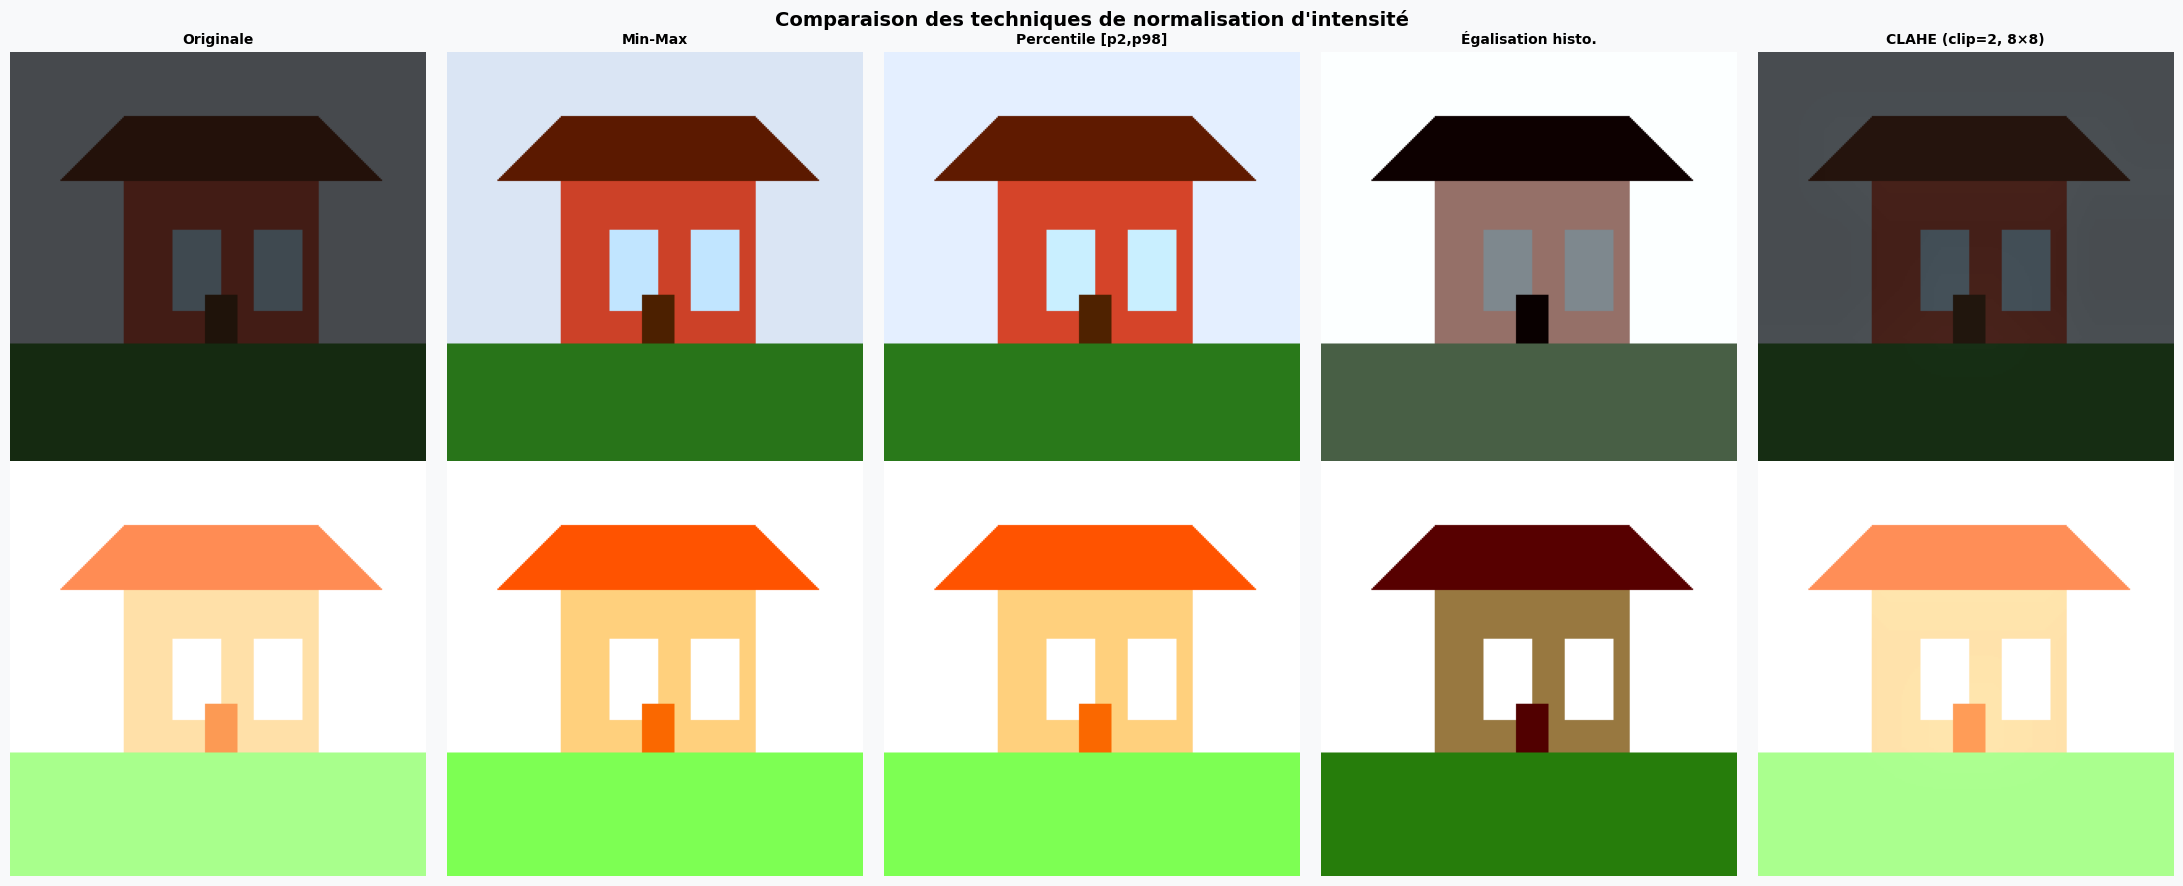

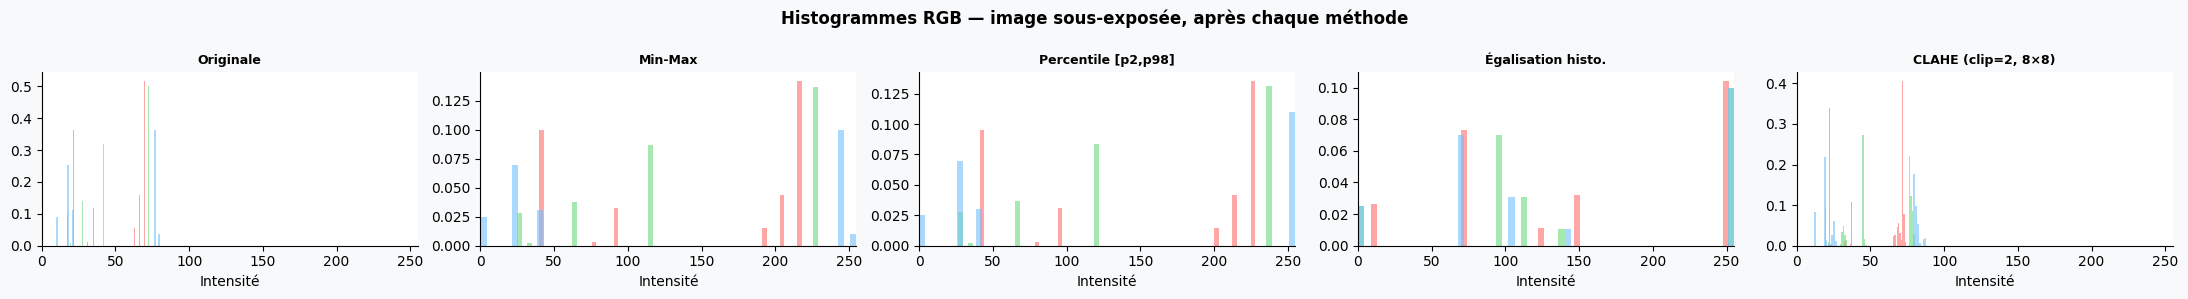

In [9]:
def normalize_minmax(img):
    img_f = img.astype(np.float32)
    mn, mx = img_f.min(), img_f.max()
    return ((img_f - mn) / (mx - mn + 1e-8) * 255).astype(np.uint8)

def normalize_percentile(img, p_low=2, p_high=98):
    img_f = img.astype(np.float32)
    lo = np.percentile(img_f, p_low)
    hi = np.percentile(img_f, p_high)
    return np.clip((img_f - lo) / (hi - lo + 1e-8) * 255, 0, 255).astype(np.uint8)

def equalize_histogram(img):
    if len(img.shape) == 3:
        img_yuv = cv2.cvtColor(img, cv2.COLOR_RGB2YUV)
        img_yuv[:,:,0] = cv2.equalizeHist(img_yuv[:,:,0])
        return cv2.cvtColor(img_yuv, cv2.COLOR_YUV2RGB)
    return cv2.equalizeHist(img)

def apply_clahe(img, clip_limit=2.0, tile_size=(8,8)):
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_size)
    if len(img.shape) == 3:
        img_lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
        img_lab[:,:,0] = clahe.apply(img_lab[:,:,0])
        return cv2.cvtColor(img_lab, cv2.COLOR_LAB2RGB)
    return clahe.apply(img)

# Test sur images sous et sur-exposées
test_imgs   = [DARK_IMG, BRIGHT_IMG]
test_labels = ["Sous-exposée", "Surexposée"]

fig, axes = plt.subplots(len(test_imgs), 5, figsize=(22, 9))
methods = [
    ("Originale",              lambda x: x),
    ("Min-Max",                normalize_minmax),
    ("Percentile [p2,p98]",    normalize_percentile),
    ("Égalisation histo.",     equalize_histogram),
    ("CLAHE (clip=2, 8×8)",    apply_clahe),
]

for row, (test_img, label) in enumerate(zip(test_imgs, test_labels)):
    for col, (method_name, method_fn) in enumerate(methods):
        result = method_fn(test_img)
        axes[row, col].imshow(result)
        title = method_name if row == 0 else ""
        ylabel = label if col == 0 else ""
        axes[row, col].set_title(title, fontsize=10)
        if col == 0:
            axes[row, col].set_ylabel(label, fontsize=11, fontweight="bold")
        axes[row, col].axis("off")

plt.suptitle("Comparaison des techniques de normalisation d'intensité",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# Histogrammes comparatifs
fig, axes = plt.subplots(1, 5, figsize=(22, 3))
dark_processed = [m(DARK_IMG) for _, m in methods]
for ax, result, (method_name, _) in zip(axes, dark_processed, methods):
    for i, color in enumerate(["#FF6B6B", "#69DB7C", "#74C0FC"]):
        ax.hist(result[:,:,i].ravel(), bins=60, color=color,
                alpha=0.6, density=True)
    ax.set_title(method_name, fontsize=9)
    ax.set_xlim(0, 255)
    ax.set_xlabel("Intensité")

fig.suptitle("Histogrammes RGB — image sous-exposée, après chaque méthode",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()



---
### 🏋️ Exercice 2 — Implémentation manuelle de l'égalisation d'histogramme

**Objectif :** Implémenter l'égalisation d'histogramme **depuis zéro** (sans `cv2.equalizeHist`) sur une image en niveaux de gris, puis vérifier visuellement le résultat.

**Rappel — les étapes :**
1. Calculer l'histogramme (256 niveaux)
2. Calculer la CDF (Cumulative Distribution Function = histogramme cumulé)
3. Normaliser la CDF pour obtenir le mapping [0, 255]
4. Appliquer le mapping pixel par pixel

<details>
<summary>💡 <strong>Hints</strong></summary>

**Hint 1 — Histogramme et CDF :**
```python
gray = (0.2126*img[:,:,0] + 0.7152*img[:,:,1] + 0.0722*img[:,:,2]).astype(np.uint8)
hist, _ = np.histogram(gray.ravel(), bins=256, range=(0, 256))
cdf     = hist.cumsum()   # CDF non normalisée
```
**Hint 2 — Normalisation de la CDF :**
```python
cdf_min = cdf[cdf > 0].min()
total   = gray.size   # H × W
mapping = np.round((cdf - cdf_min) / (total - cdf_min) * 255).astype(np.uint8)
```
**Hint 3 — Appliquer le mapping :**
```python
gray_eq = mapping[gray]   # indexation fancy NumPy !
```
**Hint 4 — Vérification :** comparez avec `cv2.equalizeHist(gray)` — les résultats doivent être identiques ou quasi-identiques.
</details>


In [ ]:
# ── Exercice 2 — À compléter ─────────────────────────────────

def equalize_histogram_manual(img_gray):
    """Égalisation d'histogramme manuelle (image niveaux de gris)."""
    # 1. Calculer l'histogramme (256 niveaux, valeurs 0-255)
    # hist, _ = np.histogram(img_gray.ravel(), bins=256, range=(0, 256))

    # 2. Calculer la CDF (histogramme cumulé)
    # cdf = hist.cumsum()

    # 3. Normaliser la CDF : mapping vers [0, 255]
    # cdf_min = cdf[cdf > 0].min()
    # total   = img_gray.size
    # mapping = np.round((cdf - cdf_min) / (total - cdf_min) * 255).astype(np.uint8)

    # 4. Appliquer le mapping pixel par pixel (via indexation NumPy)
    # return mapping[img_gray]

    return img_gray  # Remplacez cette ligne par votre implémentation


# ── Test ──────────────────────────────────────────────────────
# Convertir DARK_IMG en niveaux de gris
# gray_dark = (0.2126*DARK_IMG[:,:,0] + 0.7152*DARK_IMG[:,:,1] + 0.0722*DARK_IMG[:,:,2]).astype(np.uint8)

# Votre implémentation
# gray_eq_manual = equalize_histogram_manual(gray_dark)

# Référence OpenCV
# gray_eq_ref    = cv2.equalizeHist(gray_dark)

# Différence
# diff = np.abs(gray_eq_manual.astype(np.int16) - gray_eq_ref.astype(np.int16))
# print("Différence max avec la référence OpenCV :", diff.max())
# print("Différence moyenne :", diff.mean():.4f)

# Affichage
# fig, axes = plt.subplots(1, 4, figsize=(18, 5))
# axes[0].imshow(gray_dark,      cmap="gray"); axes[0].set_title("Originale (sombre)"); axes[0].axis("off")
# axes[1].imshow(gray_eq_manual, cmap="gray"); axes[1].set_title("Votre égalisation");  axes[1].axis("off")
# axes[2].imshow(gray_eq_ref,    cmap="gray"); axes[2].set_title("Référence OpenCV");   axes[2].axis("off")
# axes[3].imshow(diff,           cmap="hot");  axes[3].set_title("Différence (absolu)");axes[3].axis("off")
# plt.tight_layout(); plt.show()

print("Implémentez equalize_histogram_manual puis décommentez les lignes de test.")



<details>
<summary>✅ <strong>Correction</strong></summary>

```python
def equalize_histogram_manual(img_gray):
    hist, _ = np.histogram(img_gray.ravel(), bins=256, range=(0, 256))
    cdf     = hist.cumsum()
    cdf_min = cdf[cdf > 0].min()
    total   = img_gray.size
    mapping = np.round((cdf - cdf_min) / (total - cdf_min) * 255).clip(0,255).astype(np.uint8)
    return mapping[img_gray]

gray_dark      = (0.2126*DARK_IMG[:,:,0]+0.7152*DARK_IMG[:,:,1]+0.0722*DARK_IMG[:,:,2]).astype(np.uint8)
gray_eq_manual = equalize_histogram_manual(gray_dark)
gray_eq_ref    = cv2.equalizeHist(gray_dark)
diff = np.abs(gray_eq_manual.astype(np.int16) - gray_eq_ref.astype(np.int16))
print("Diff max:", diff.max(), " | moy:", diff.mean().round(4))
```
</details>



---
### 🏋️ Exercice 3 — CLAHE : trouver les bons hyperparamètres

**Objectif :** Appliquer CLAHE avec différentes valeurs de `clip_limit` (1, 2, 4, 8) et de `tile_size` (4×4, 8×8, 16×16) sur `BRIGHT_IMG`, et déterminer quelle combinaison donne le meilleur résultat visuellement.

<details>
<summary>💡 <strong>Hints</strong></summary>

**Hint 1 — Créer un CLAHE avec OpenCV :**
```python
clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_size)
```
**Hint 2 — Appliquer sur le canal L de l'espace LAB :**
```python
img_lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
img_lab[:,:,0] = clahe.apply(img_lab[:,:,0])
result = cv2.cvtColor(img_lab, cv2.COLOR_LAB2RGB)
```
**Hint 3 — Grille d'expériences :**
```python
clip_limits = [1.0, 2.0, 4.0, 8.0]
tile_sizes  = [(4,4), (8,8), (16,16)]
# → grid 4×3 = 12 images
```
</details>


In [ ]:
# ── Exercice 3 — À compléter ─────────────────────────────────
clip_limits = [1.0, 2.0, 4.0, 8.0]
tile_sizes  = [(4,4), (8,8), (16,16)]

# Conseil : créez une figure avec un subplot par combinaison (4 lignes × 3 colonnes)
# fig, axes = plt.subplots(len(clip_limits), len(tile_sizes), figsize=(12, 16))
# for i, clip in enumerate(clip_limits):
#     for j, tile in enumerate(tile_sizes):
#         clahe   = cv2.createCLAHE(clipLimit=clip, tileGridSize=tile)
#         lab     = cv2.cvtColor(BRIGHT_IMG, cv2.COLOR_RGB2LAB)
#         lab[:,:,0] = clahe.apply(lab[:,:,0])
#         result  = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)
#         axes[i,j].imshow(result)
#         axes[i,j].set_title("clip=%.1f, tile=%s" % (clip, str(tile)), fontsize=9)
#         axes[i,j].axis("off")
# plt.suptitle("CLAHE — exploration des hyperparamètres (image surexposée)", fontsize=13, fontweight="bold")
# plt.tight_layout(); plt.show()

print("Décommentez et complétez le code pour explorer les hyperparamètres CLAHE.")



---
<div style="background:linear-gradient(90deg,#0F2044,#1A4A8A);padding:20px 28px;border-radius:10px;border-left:7px solid #F97316;">
  <h1 style="color:#F97316;margin:0;font-size:1.65em;">🌊 Module 3 — Débruitage & filtrage spatial</h1>
  <p style="color:#B0C4DE;margin:6px 0 0 0;">Supprimer le bruit tout en préservant les contours</p>
</div>



### 📖 Rappel théorique

#### Types de bruit en imagerie numérique

| Type de bruit | Origine | Modèle |
|--------------|---------|--------|
| **Gaussien** | Électronique du capteur | $I_{noisy} = I + \mathcal{N}(0, \sigma^2)$ |
| **Sel & poivre** | Pixels défectueux, transmission | Pixels aléatoires à 0 ou 255 |
| **Poisson (shot noise)** | Faible luminosité, photons | $I_{noisy} \sim Poisson(I)$ |
| **Speckle** | Imagerie radar/ultrasons | $I_{noisy} = I \cdot \mathcal{N}(1, \sigma^2)$ |

#### Filtres de lissage

```
Filtre moyen (box filter) :
    Noyau = [[1,1,1],[1,1,1],[1,1,1]] / 9
    → Simple, rapide, mais floute les contours

Filtre gaussien :
    Noyau = gaussienne 2D, sigma contrôle le rayon
    → Lissage doux, préserve mieux les structures

Filtre médian :
    Remplace chaque pixel par la médiane de son voisinage
    → Excellent contre sel & poivre, préserve les contours nets

Filtre bilatéral :
    Pondère par similarité spatiale ET photométrique
    → Lisse le bruit, PRÉSERVE les bords — mais lent

Non-local means (NLM) :
    Compare des patches similaires dans toute l'image
    → Très haute qualité, coûteux en calcul
```

#### Métriques de qualité
- **PSNR** (Peak Signal-to-Noise Ratio) : $PSNR = 20 \log_{10}(255/RMSE)$ — en dB, plus élevé = mieux
- **SSIM** (Structural Similarity) : similarité structurelle, ∈ [-1, 1], 1 = identique


### 🔬 Démonstration — Comparaison des filtres de débruitage

In [ ]:
from skimage.metrics import peak_signal_noise_ratio as psnr, structural_similarity as ssim

# ── Types de bruit ────────────────────────────────────────────
def add_gaussian_noise(img, sigma=30):
    noise = np.random.randn(*img.shape) * sigma
    return np.clip(img.astype(np.float32) + noise, 0, 255).astype(np.uint8)

def add_salt_pepper(img, density=0.05):
    result = img.copy()
    mask   = np.random.rand(img.shape[0], img.shape[1])
    result[mask < density/2]        = 0
    result[mask > 1 - density/2]    = 255
    return result

def add_speckle(img, sigma=0.2):
    noise = np.random.randn(*img.shape) * sigma
    return np.clip(img.astype(np.float32) * (1 + noise), 0, 255).astype(np.uint8)

np.random.seed(0)
img_gauss = add_gaussian_noise(BASE_IMG, sigma=35)
img_sp    = add_salt_pepper(BASE_IMG, density=0.08)
img_speck = add_speckle(BASE_IMG, sigma=0.25)

# ── Filtres de débruitage ─────────────────────────────────────
def metrics_str(original, denoised):
    p = psnr(original, denoised, data_range=255)
    s = ssim(original, denoised, channel_axis=2, data_range=255)
    return f"PSNR={p:.1f}dB  SSIM={s:.3f}"

filters_info = [
    ("Moyen 5×5",      lambda x: cv2.blur(x, (5, 5))),
    ("Gaussien σ=2",   lambda x: cv2.GaussianBlur(x, (9, 9), 2)),
    ("Médian k=5",     lambda x: cv2.medianBlur(x, 5)),
    ("Bilatéral",      lambda x: cv2.bilateralFilter(x, d=9, sigmaColor=75, sigmaSpace=75)),
]

fig, axes = plt.subplots(3, 5, figsize=(24, 15))
noisy_imgs  = [img_gauss, img_sp, img_speck]
noise_names = ["Bruit gaussien (σ=35)", "Sel & Poivre (d=8%)", "Speckle (σ=0.25)"]

for row, (noisy, noise_name) in enumerate(zip(noisy_imgs, noise_names)):
    axes[row, 0].imshow(noisy)
    axes[row, 0].set_title("Bruité  " + metrics_str(BASE_IMG, noisy), fontsize=9)
    axes[row, 0].set_ylabel(noise_name, fontsize=10, fontweight="bold")
    axes[row, 0].axis("off")

    for col, (fname, ffn) in enumerate(filters_info):
        result = ffn(noisy)
        axes[row, col+1].imshow(result)
        axes[row, col+1].set_title(fname + "  " + metrics_str(BASE_IMG, result), fontsize=9)
        axes[row, col+1].axis("off")

plt.suptitle("Filtres de débruitage selon le type de bruit (PSNR/SSIM vs image propre)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()



---
### 🏋️ Exercice 4 — Débruitage sélectif : le meilleur filtre pour chaque bruit

**Objectif :** Pour chaque type de bruit (gaussien, sel & poivre, speckle) :
1. Appliquer **tous les filtres** disponibles
2. Calculer PSNR et SSIM
3. Identifier **automatiquement** le filtre optimal par type de bruit
4. Afficher un tableau récapitulatif

<details>
<summary>💡 <strong>Hints</strong></summary>

**Hint 1 — Calculer PSNR et SSIM :**
```python
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

p = psnr(original, denoised, data_range=255)
s = ssim(original, denoised, channel_axis=2, data_range=255)
```
**Hint 2 — Stocker les résultats dans un dictionnaire :**
```python
results = {}   # results[noise_type][filter_name] = {"psnr": p, "ssim": s}
```
**Hint 3 — Trouver le meilleur filtre :**
```python
best = max(results[noise_type].keys(), key=lambda k: results[noise_type][k]["psnr"])
```
</details>


In [ ]:
# ── Exercice 4 — À compléter ─────────────────────────────────
# from skimage.metrics import peak_signal_noise_ratio as psnr, structural_similarity as ssim

# Dictionnaire de bruits
# noisy_dict = {
#     "Gaussien (σ=35)":  img_gauss,
#     "Sel & Poivre (8%)": img_sp,
#     "Speckle (0.25)":   img_speck,
# }

# Dictionnaire de filtres
# filters_dict = {
#     "Moyen 5×5":     lambda x: cv2.blur(x, (5, 5)),
#     "Gaussien σ=2":  lambda x: cv2.GaussianBlur(x, (9,9), 2),
#     "Médian k=5":    lambda x: cv2.medianBlur(x, 5),
#     "Bilatéral":     lambda x: cv2.bilateralFilter(x, 9, 75, 75),
# }

# Calculer PSNR et SSIM pour chaque combinaison (bruit × filtre)
# results = {}
# for noise_name, noisy_img in noisy_dict.items():
#     results[noise_name] = {}
#     for filter_name, filter_fn in filters_dict.items():
#         denoised = filter_fn(noisy_img)
#         p = psnr(BASE_IMG, denoised, data_range=255)
#         s = ssim(BASE_IMG, denoised, channel_axis=2, data_range=255)
#         results[noise_name][filter_name] = {"psnr": p, "ssim": s}

# Afficher le tableau et le meilleur filtre par bruit
# print(f"{'':25} {'Moyen':>14} {'Gaussien':>14} {'Médian':>14} {'Bilatéral':>14}")
# print("-" * 82)
# for noise_name in results:
#     psnr_vals = [results[noise_name][f]["psnr"] for f in filters_dict]
#     best_idx  = np.argmax(psnr_vals)
#     print(f"{noise_name:25}", end="")
#     for i, (fname, vals) in enumerate(results[noise_name].items()):
#         marker = " ★" if i == best_idx else "  "
#         print(f"  {vals['psnr']:5.1f}dB{marker}", end="")
#     print()

print("Implémentez la boucle d'évaluation et décommentez le code ci-dessus.")



---
### 🏋️ Exercice 5 — Non-Local Means : comprendre l'effet des paramètres

**Objectif :** Appliquer le filtre Non-Local Means (NLM) de scikit-image sur l'image gaussienne bruitée avec différentes valeurs de `h` (force de débruitage), et observer l'effet sur le PSNR.

<details>
<summary>💡 <strong>Hints</strong></summary>

**Hint 1 — NLM avec scikit-image :**
```python
from skimage.restoration import denoise_nl_means, estimate_sigma
sigma_est = estimate_sigma(img_gauss, channel_axis=-1, average_sigmas=True)
denoised  = denoise_nl_means(img_gauss, h=1.15*sigma_est, fast_mode=True,
                              patch_size=5, patch_distance=6, channel_axis=-1)
# Convertir en uint8
denoised_u8 = (denoised * 255).clip(0,255).astype(np.uint8)
```
**Hint 2 — Tester plusieurs valeurs de h :**
```python
h_factors = [0.6, 0.8, 1.0, 1.2, 1.5, 2.0]   # multiplicateur de sigma_est
```
</details>


In [ ]:
# ── Exercice 5 — À compléter ─────────────────────────────────
# from skimage.restoration import denoise_nl_means, estimate_sigma
# from skimage.metrics import peak_signal_noise_ratio as psnr

# 1. Estimer sigma du bruit
# sigma_est = estimate_sigma(img_gauss, channel_axis=-1, average_sigmas=True)
# print("Sigma estimé :", round(sigma_est * 255, 2))

# 2. Tester différents facteurs h
# h_factors  = [0.6, 0.8, 1.0, 1.2, 1.5, 2.0]
# results_nlm = []

# for hf in h_factors:
#     denoised = denoise_nl_means(
#         img_gauss.astype(np.float32) / 255.0,
#         h=hf * sigma_est,
#         fast_mode=True,
#         patch_size=5,
#         patch_distance=6,
#         channel_axis=-1
#     )
#     denoised_u8 = (denoised * 255).clip(0, 255).astype(np.uint8)
#     p = psnr(BASE_IMG, denoised_u8, data_range=255)
#     results_nlm.append((hf, denoised_u8, p))
#     print(f"  h = {hf:.1f} × sigma_est → PSNR = {p:.2f} dB")

# 3. Afficher les 6 résultats + courbe PSNR vs h
# fig, axes = plt.subplots(2, 6, figsize=(24, 8))
# for i, (hf, img_d, p) in enumerate(results_nlm):
#     axes[0, i].imshow(img_d); axes[0, i].set_title("h=%.1f*s | PSNR=%.1fdB" % (hf, p), fontsize=9)
#     axes[0, i].axis("off")
# axes[1, 0].plot([r[0] for r in results_nlm], [r[2] for r in results_nlm],
#                 "o-", color=BLUE, linewidth=2, markersize=8)
# axes[1, 0].set_xlabel("Facteur h / sigma_est"); axes[1, 0].set_ylabel("PSNR (dB)")
# axes[1, 0].set_title("PSNR vs force de débruitage NLM"); axes[1, 0].grid(True, alpha=0.3)
# for ax in axes[1, 1:]: ax.set_visible(False)
# plt.tight_layout(); plt.show()

print("Décommentez le code pour explorer le Non-Local Means.")



---
<div style="background:linear-gradient(90deg,#0F2044,#1A4A8A);padding:20px 28px;border-radius:10px;border-left:7px solid #22C55E;">
  <h1 style="color:#22C55E;margin:0;font-size:1.65em;">📐 Module 4 — Redimensionnement, recadrage & transformations géométriques</h1>
  <p style="color:#B0C4DE;margin:6px 0 0 0;">Adapter la résolution aux besoins des réseaux</p>
</div>



### 📖 Rappel théorique

#### Pourquoi redimensionner ?

Les CNN ont des couches entièrement connectées qui attendent **une taille fixe en entrée** (ex : ResNet attend 224×224, YOLO 640×640). Le redimensionnement est donc obligatoire.

#### Méthodes d'interpolation

| Méthode | Principe | Quand utiliser |
|---------|----------|----------------|
| **Nearest Neighbor** | Pixel le plus proche | Masques de segmentation (préserve les labels) |
| **Bilinéaire** | Interpolation 2×2 pixels | Bon compromis vitesse/qualité |
| **Bicubique** | Interpolation 4×4 pixels | Meilleure qualité, plus lent |
| **Lanczos** | Filtre sinusoïdal | Très haute qualité (downscaling) |
| **Area** | Moyenne de la zone | Downscaling uniquement, anti-aliasing optimal |

#### Stratégies de redimensionnement

```
1. Stretch (distorsion)   : étirer sans conserver le ratio → déformations
2. Fit + Padding (letterbox) : zoom uniforme + bandes noires → ratio conservé ✓
3. Center Crop           : recadrage centré → perd les bords
4. Random Crop           : recadrage aléatoire → data augmentation
5. Pad + Resize          : padder avant de scaler → ratio conservé ✓
```

> ⚠️ Pour les **masques de segmentation** : toujours utiliser `INTER_NEAREST` pour ne pas interpoler les labels (ex: classe 3 ≠ 2.7).


### 🔬 Démonstration — Méthodes de redimensionnement

In [ ]:
TARGET_SIZE = (128, 128)

def resize_stretch(img, size):
    return cv2.resize(img, size, interpolation=cv2.INTER_LINEAR)

def resize_letterbox(img, size, pad_color=(0, 0, 0)):
    h, w = img.shape[:2]
    target_w, target_h = size
    scale   = min(target_w / w, target_h / h)
    new_w   = int(w * scale)
    new_h   = int(h * scale)
    resized = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_LINEAR)
    canvas  = np.full((target_h, target_w, 3), pad_color, dtype=np.uint8)
    x_off   = (target_w - new_w) // 2
    y_off   = (target_h - new_h) // 2
    canvas[y_off:y_off+new_h, x_off:x_off+new_w] = resized
    return canvas

def resize_center_crop(img, size):
    h, w = img.shape[:2]
    target_w, target_h = size
    scale   = max(target_w / w, target_h / h)
    new_w, new_h = int(w * scale), int(h * scale)
    resized = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_LINEAR)
    x_off   = (new_w - target_w) // 2
    y_off   = (new_h - target_h) // 2
    return resized[y_off:y_off+target_h, x_off:x_off+target_w]

# Image rectangulaire pour voir l'effet du ratio
img_rect = BASE_IMG[:, 50:210, :]   # 256×160 (portrait)

methods_resize = [
    ("Originale (%dx%d)" % (img_rect.shape[1], img_rect.shape[0]), img_rect),
    ("Stretch (128x128)", resize_stretch(img_rect, TARGET_SIZE)),
    ("Letterbox (128x128)", resize_letterbox(img_rect, TARGET_SIZE)),
    ("Center Crop (128x128)", resize_center_crop(img_rect, TARGET_SIZE)),
]

# Comparaison des interpolations
interp_methods = [
    ("NEAREST",  cv2.INTER_NEAREST),
    ("BILINEAR", cv2.INTER_LINEAR),
    ("BICUBIC",  cv2.INTER_CUBIC),
    ("LANCZOS",  cv2.INTER_LANCZOS4),
    ("AREA",     cv2.INTER_AREA),
]
small = cv2.resize(BASE_IMG, (32, 32), interpolation=cv2.INTER_AREA)
upscaled = [(name, cv2.resize(small, (128, 128), interpolation=interp))
            for name, interp in interp_methods]

fig = plt.figure(figsize=(22, 10))
gs  = gridspec.GridSpec(2, 9, figure=fig)

# Ligne 1 : stratégies de redimensionnement
for i, (title, img_r) in enumerate(methods_resize):
    ax = fig.add_subplot(gs[0, i*2:(i+1)*2])
    ax.imshow(img_r)
    ax.set_title(title, fontsize=10)
    ax.axis("off")
    if i > 0:
        # Encadrer les zones modifiées
        pass

# Ligne 2 : méthodes d'interpolation (upscaling ×4)
ax_small = fig.add_subplot(gs[1, 0])
ax_small.imshow(small); ax_small.set_title("Original | 32×32", fontsize=10); ax_small.axis("off")

for i, (name, img_up) in enumerate(upscaled):
    ax = fig.add_subplot(gs[1, i+1])
    ax.imshow(img_up); ax.set_title(name + " | 128×128", fontsize=10); ax.axis("off")
ax_small2 = fig.add_subplot(gs[1, -1])
ax_small2.imshow(BASE_IMG); ax_small2.set_title("Référence | 256×256", fontsize=10); ax_small2.axis("off")

plt.suptitle("Stratégies de redimensionnement (haut) vs méthodes d'interpolation upscaling ×4 (bas)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()



---
### 🏋️ Exercice 6 — Letterbox universel avec visualisation des bandes

**Objectif :** Créer une fonction `letterbox_with_info` qui :
1. Redimensionne en conservant le ratio (letterbox)
2. Retourne l'image + les paramètres de transformation (scale, offset_x, offset_y)
3. Permet de reconstruire les coordonnées originales d'un point détecté dans l'image redimensionnée

**Cas d'usage :** Dans YOLO, les bounding boxes prédites sur l'image 640×640 doivent être ramenées aux coordonnées originales.

<details>
<summary>💡 <strong>Hints</strong></summary>

**Hint 1 — Calculer scale et offsets :**
```python
scale = min(target_w / orig_w, target_h / orig_h)
new_w, new_h = int(orig_w * scale), int(orig_h * scale)
off_x = (target_w - new_w) // 2
off_y = (target_h - new_h) // 2
```
**Hint 2 — Inverse transform (résolution → original) :**
```python
def to_original_coords(x_resized, y_resized, scale, off_x, off_y):
    x_orig = (x_resized - off_x) / scale
    y_orig = (y_resized - off_y) / scale
    return x_orig, y_orig
```
**Hint 3 — Visualiser les bandes :** les bandes de padding correspondent aux pixels **hors** de la zone `[off_y:off_y+new_h, off_x:off_x+new_w]`.
</details>


In [ ]:
# ── Exercice 6 — À compléter ─────────────────────────────────

def letterbox_with_info(img, target_size=(128, 128), pad_color=(114, 114, 114)):
    """
    Redimensionne en conservant le ratio (letterbox).
    Retourne (img_resized, scale, off_x, off_y)
    """
    h, w = img.shape[:2]
    target_w, target_h = target_size

    # 1. Calculer le facteur d'échelle et les nouvelles dimensions
    # scale = min(target_w / w, target_h / h)
    # new_w = int(w * scale)
    # new_h = int(h * scale)

    # 2. Redimensionner
    # resized = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_LINEAR)

    # 3. Créer le canvas et calculer les offsets
    # canvas = np.full((target_h, target_w, 3), pad_color, dtype=np.uint8)
    # off_x  = (target_w - new_w) // 2
    # off_y  = (target_h - new_h) // 2
    # canvas[off_y:off_y+new_h, off_x:off_x+new_w] = resized

    # return canvas, scale, off_x, off_y

    return img, 1.0, 0, 0  # Remplacez par votre implémentation


def to_original_coords(x_r, y_r, scale, off_x, off_y):
    """Convertit des coordonnées dans l'image letterboxée vers l'image originale."""
    # x_orig = (x_r - off_x) / scale
    # y_orig = (y_r - off_y) / scale
    # return int(x_orig), int(y_orig)
    return int(x_r), int(y_r)  # Remplacez par votre implémentation


# ── Test ──────────────────────────────────────────────────────
# img_lb, scale, off_x, off_y = letterbox_with_info(BASE_IMG, target_size=(200, 128))

# Point de test dans l'image redimensionnée (centre de la porte)
# x_lb, y_lb = 100, 110   # coordonnées dans l'image 200×128
# x_orig, y_orig = to_original_coords(x_lb, y_lb, scale, off_x, off_y)
# print(f"Point dans letterbox : ({x_lb}, {y_lb})")
# print(f"Point dans originale : ({x_orig}, {y_orig})")
# print(f"Scale={scale:.3f}  off_x={off_x}  off_y={off_y}")

# Visualiser : marquer le même point sur les deux images
# fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
# ax1.imshow(img_lb)
# ax1.plot(x_lb, y_lb, "r+", markersize=15, markeredgewidth=3)
# ax1.set_title(f"Letterbox ({img_lb.shape[1]}×{img_lb.shape[0]})")
# ax1.axis("off")
# ax2.imshow(BASE_IMG)
# ax2.plot(x_orig, y_orig, "r+", markersize=15, markeredgewidth=3)
# ax2.set_title(f"Originale ({BASE_IMG.shape[1]}×{BASE_IMG.shape[0]})")
# ax2.axis("off")
# plt.tight_layout(); plt.show()

print("Implémentez letterbox_with_info et to_original_coords, puis décommentez le test.")



---
<div style="background:linear-gradient(90deg,#0F2044,#1A4A8A);padding:20px 28px;border-radius:10px;border-left:7px solid #9B59B6;">
  <h1 style="color:#9B59B6;margin:0;font-size:1.65em;">🔄 Module 5 — Transformations géométriques avancées</h1>
  <p style="color:#B0C4DE;margin:6px 0 0 0;">Rotation, flip, perspective, transformations affines</p>
</div>



### 📖 Rappel théorique

#### Hiérarchie des transformations

```
Euclidienne (isométrie)        : translation + rotation              [preserve distances]
Similitude                     : + scale uniforme                    [preserve angles]
Affine                         : + scale non-uniforme, cisaillement  [préserve paralléles]
Projective (homographie)       : + perspective                       [préserve lignes droites]
```

#### Matrice de transformation affine (2D)

$$\begin{pmatrix} x' \\ y' \end{pmatrix} = \begin{pmatrix} a_{11} & a_{12} \\ a_{21} & a_{22} \end{pmatrix} \begin{pmatrix} x \\ y \end{pmatrix} + \begin{pmatrix} t_x \\ t_y \end{pmatrix}$$

Avec OpenCV :
```python
M = cv2.getRotationMatrix2D(center, angle, scale)   # rotation + zoom
img_rot = cv2.warpAffine(img, M, (W, H))
```

#### Transformations courantes en Data Augmentation

| Transformation | Paramètre | Réalisme |
|---------------|-----------|---------|
| Flip horizontal | Toujours | ✅ Naturel pour la plupart des scènes |
| Flip vertical | Selon domaine | ⚠️ Non réaliste pour les véhicules |
| Rotation ±15° | Léger | ✅ Naturel |
| Rotation ±90° | Fort | ⚠️ Selon domaine (pathologie = OK) |
| Cisaillement ±10° | Léger | ✅ Naturel |
| Perspective | Faible | ✅ Simule angle de caméra |
| Elastic deformation | Faible | ✅ Tissus biologiques |


### 🔬 Démonstration — Transformations géométriques

In [ ]:
h, w = BASE_IMG.shape[:2]

# ── Rotation ──────────────────────────────────────────────────
def rotate(img, angle, scale=1.0, keep_size=True):
    h, w = img.shape[:2]
    center = (w // 2, h // 2)
    M = cv2.getRotationMatrix2D(center, angle, scale)
    if keep_size:
        return cv2.warpAffine(img, M, (w, h), borderMode=cv2.BORDER_REFLECT)
    # Calculer la taille du canvas étendu
    cos, sin = abs(M[0,0]), abs(M[0,1])
    new_w = int(h*sin + w*cos)
    new_h = int(h*cos + w*sin)
    M[0,2] += (new_w - w) / 2
    M[1,2] += (new_h - h) / 2
    return cv2.warpAffine(img, M, (new_w, new_h), borderMode=cv2.BORDER_REFLECT)

# ── Cisaillement ──────────────────────────────────────────────
def shear(img, shear_x=0.15, shear_y=0.0):
    h, w = img.shape[:2]
    M = np.array([[1, shear_x, 0],
                  [shear_y, 1, 0]], dtype=np.float32)
    new_w = int(w + abs(shear_x) * h)
    new_h = int(h + abs(shear_y) * w)
    return cv2.warpAffine(img, M, (new_w, new_h), borderMode=cv2.BORDER_REFLECT)

# ── Transformation perspective ────────────────────────────────
def perspective_transform(img, strength=0.1):
    h, w = img.shape[:2]
    d = int(min(h, w) * strength)
    src = np.float32([[0,0], [w,0], [w,h], [0,h]])
    dst = np.float32([[d,d], [w-d,d//2], [w-d//2,h-d//2], [d//2,h-d]])
    M = cv2.getPerspectiveTransform(src, dst)
    return cv2.warpPerspective(img, M, (w, h), borderMode=cv2.BORDER_REFLECT)

# ── Transformation élastique ──────────────────────────────────
def elastic_transform(img, alpha=30, sigma=5):
    h, w = img.shape[:2]
    dx = cv2.GaussianBlur((np.random.rand(h, w) * 2 - 1).astype(np.float32),
                           (0, 0), sigma) * alpha
    dy = cv2.GaussianBlur((np.random.rand(h, w) * 2 - 1).astype(np.float32),
                           (0, 0), sigma) * alpha
    x, y = np.meshgrid(np.arange(w), np.arange(h))
    map_x = np.clip(x + dx, 0, w - 1).astype(np.float32)
    map_y = np.clip(y + dy, 0, h - 1).astype(np.float32)
    return cv2.remap(img, map_x, map_y, cv2.INTER_LINEAR)

np.random.seed(7)
transforms = [
    ("Original",             BASE_IMG),
    ("Flip horizontal",      BASE_IMG[:, ::-1, :]),
    ("Flip vertical",        BASE_IMG[::-1, :, :]),
    ("Rotation +15°",        rotate(BASE_IMG, 15)),
    ("Rotation -30°",        rotate(BASE_IMG, -30)),
    ("Cisaillement X 0.15",  shear(BASE_IMG, 0.15, 0.0)[:h, :w]),
    ("Perspective",          perspective_transform(BASE_IMG, 0.08)),
    ("Élastique (α=30,σ=5)", elastic_transform(BASE_IMG, 30, 5)),
]

show_grid([t[1] for t in transforms], [t[0] for t in transforms],
          ncols=4, figsize=(20, 10))



---
### 🏋️ Exercice 7 — Augmentation géométrique avec labels

**Contexte :** En détection d'objets, quand on applique une transformation géométrique à l'image, il faut aussi transformer les **bounding boxes** associées.

**Objectif :** Implémenter un flip horizontal qui transforme aussi une bounding box `(x_min, y_min, x_max, y_max)`, puis visualiser l'image et la box avant/après.

La bounding box de la porte dans `BASE_IMG` est : `(120, 150, 140, 180)` → `(x_min, y_min, x_max, y_max)`.

<details>
<summary>💡 <strong>Hints</strong></summary>

**Hint 1 — Flip horizontal de l'image :**
```python
img_flipped = img[:, ::-1, :]   # ou np.fliplr(img)
```
**Hint 2 — Transformation de la bounding box :**
Après un flip horizontal sur une image de largeur W :
```python
x_min_new = W - x_max_orig
x_max_new = W - x_min_orig
# y_min et y_max ne changent pas
```
**Hint 3 — Dessiner une bounding box sur une image :**
```python
import matplotlib.patches as patches
rect = patches.Rectangle((x_min, y_min), x_max-x_min, y_max-y_min,
                           linewidth=2, edgecolor="red", facecolor="none")
ax.add_patch(rect)
```
</details>


In [ ]:
import matplotlib.patches as patches

# Bounding box de la porte : (x_min, y_min, x_max, y_max)
bbox_orig = (120, 150, 140, 180)   # porte dans BASE_IMG

# ── Exercice 7 — À compléter ─────────────────────────────────

def flip_horizontal_with_bbox(img, bbox):
    """
    Applique un flip horizontal sur img et transforme la bounding box.
    bbox : (x_min, y_min, x_max, y_max)
    Retourne : (img_flipped, bbox_flipped)
    """
    W = img.shape[1]
    # 1. Flip de l'image
    # img_flipped = img[:, ::-1, :]

    # 2. Transformation des coordonnées
    # x_min_new = W - bbox[2]
    # x_max_new = W - bbox[0]
    # bbox_flipped = (x_min_new, bbox[1], x_max_new, bbox[3])

    # return img_flipped, bbox_flipped
    return img, bbox   # Remplacez par votre implémentation


# Test et visualisation
# img_flipped, bbox_flipped = flip_horizontal_with_bbox(BASE_IMG, bbox_orig)

# fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))
# ax1.imshow(BASE_IMG)
# x0, y0, x1, y1 = bbox_orig
# rect = patches.Rectangle((x0, y0), x1-x0, y1-y0, linewidth=3, edgecolor=RED, facecolor="none")
# ax1.add_patch(rect)
# ax1.set_title("Image originale + bbox porte"); ax1.axis("off")

# ax2.imshow(img_flipped)
# x0f, y0f, x1f, y1f = bbox_flipped
# rect_f = patches.Rectangle((x0f, y0f), x1f-x0f, y1f-y0f, linewidth=3, edgecolor=GREEN, facecolor="none")
# ax2.add_patch(rect_f)
# ax2.set_title("Après flip horizontal + bbox transformée"); ax2.axis("off")
# plt.tight_layout(); plt.show()
# print(f"Bbox originale : {bbox_orig}")
# print(f"Bbox flippée   : {bbox_flipped}")

print("Implémentez flip_horizontal_with_bbox puis décommentez la visualisation.")



---
<div style="background:linear-gradient(90deg,#0F2044,#1A4A8A);padding:20px 28px;border-radius:10px;border-left:7px solid #F97316;">
  <h1 style="color:#F97316;margin:0;font-size:1.65em;">🎨 Module 6 — Data Augmentation photométrique</h1>
  <p style="color:#B0C4DE;margin:6px 0 0 0;">Variations de couleur, luminosité, contraste — simuler des conditions d'éclairage réelles</p>
</div>



### 📖 Rappel théorique

#### Pourquoi l'augmentation photométrique ?

En conditions réelles, la même scène peut être capturée :
- À différents moments de la journée (couleur de la lumière change)
- Par différentes caméras (balance des blancs différente)
- Dans des conditions météo variées (brume, pluie, nuit)

L'augmentation photométrique entraîne le modèle à être **robuste** à ces variations.

#### Transformations photométriques

| Transformation | Paramètre | Formule |
|---------------|-----------|---------|
| **Luminosité** | β ∈ [0.5, 1.5] | `I' = clip(I × β, 0, 255)` |
| **Contraste** | α ∈ [0.5, 1.5] | `I' = clip(α × I + 127(1-α), 0, 255)` |
| **Gamma** | γ ∈ [0.5, 2.0] | `I' = (I/255)^γ × 255` |
| **Saturation** (HSV) | s ∈ [0, 2] | Multiplier canal S en HSV |
| **Teinte** (HSV) | Δh ∈ [-30, 30] | Décaler canal H en HSV |
| **Color Jitter** | Tout en même temps | Combinaison aléatoire |
| **Grayscale mix** | p ∈ [0, 1] | Mélange avec la version grise |
| **Channel shuffle** | — | Permuter les canaux RGB |
| **Solarisation** | threshold | Inverser les pixels > seuil |
| **Posterisation** | bits ∈ [2, 8] | Réduire la profondeur de couleur |

> ⚠️ Appliquer des augmentations aléatoires à chaque epoch, pas une fois pour toutes !


### 🔬 Démonstration — Transformations photométriques

In [ ]:
def adjust_brightness(img, beta):
    return np.clip(img.astype(np.float32) * beta, 0, 255).astype(np.uint8)

def adjust_contrast(img, alpha):
    img_f = img.astype(np.float32)
    return np.clip(alpha * img_f + 127 * (1 - alpha), 0, 255).astype(np.uint8)

def gamma_correction(img, gamma):
    lut = np.array([(i / 255.0) ** gamma * 255 for i in range(256)], dtype=np.uint8)
    return lut[img]

def adjust_saturation(img, factor):
    img_hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV).astype(np.float32)
    img_hsv[:,:,1] = np.clip(img_hsv[:,:,1] * factor, 0, 255)
    return cv2.cvtColor(img_hsv.astype(np.uint8), cv2.COLOR_HSV2RGB)

def adjust_hue(img, delta_h):
    img_hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV).astype(np.int16)
    img_hsv[:,:,0] = (img_hsv[:,:,0] + delta_h) % 180
    return cv2.cvtColor(img_hsv.astype(np.uint8), cv2.COLOR_HSV2RGB)

def solarize(img, threshold=128):
    result = img.copy()
    result[img >= threshold] = 255 - img[img >= threshold]
    return result

def posterize(img, bits=4):
    shift = 8 - bits
    return ((img >> shift) << shift)

def grayscale_mix(img, alpha=0.5):
    gray = (0.2126*img[:,:,0] + 0.7152*img[:,:,1] + 0.0722*img[:,:,2]).astype(np.uint8)
    gray3 = np.stack([gray]*3, axis=2)
    return np.clip(alpha*img.astype(np.float32) + (1-alpha)*gray3.astype(np.float32), 0, 255).astype(np.uint8)

def color_jitter(img, brightness=0.3, contrast=0.3, saturation=0.3, hue=15):
    b  = np.random.uniform(1-brightness, 1+brightness)
    c  = np.random.uniform(1-contrast,   1+contrast)
    s  = np.random.uniform(1-saturation, 1+saturation)
    dh = np.random.uniform(-hue, hue)
    result = adjust_brightness(img, b)
    result = adjust_contrast(result, c)
    result = adjust_saturation(result, s)
    result = adjust_hue(result, int(dh))
    return result

photometric_transforms = [
    ("Original",            BASE_IMG),
    ("Luminosité ×0.4",     adjust_brightness(BASE_IMG, 0.4)),
    ("Luminosité ×1.8",     adjust_brightness(BASE_IMG, 1.8)),
    ("Contraste α=0.4",     adjust_contrast(BASE_IMG, 0.4)),
    ("Contraste α=2.0",     adjust_contrast(BASE_IMG, 2.0)),
    ("Gamma γ=0.4",         gamma_correction(BASE_IMG, 0.4)),
    ("Gamma γ=2.0",         gamma_correction(BASE_IMG, 2.0)),
    ("Saturation ×0.0",     adjust_saturation(BASE_IMG, 0.0)),
    ("Saturation ×2.5",     adjust_saturation(BASE_IMG, 2.5)),
    ("Teinte +45°",         adjust_hue(BASE_IMG, 45)),
    ("Solarisation >128",   solarize(BASE_IMG, 128)),
    ("Postérisation 3bits", posterize(BASE_IMG, 3)),
    ("GrayMix α=0.5",       grayscale_mix(BASE_IMG, 0.5)),
    ("Color Jitter",        color_jitter(BASE_IMG)),
    ("Color Jitter (2)",    color_jitter(BASE_IMG)),
    ("Color Jitter (3)",    color_jitter(BASE_IMG)),
]

show_grid([t[1] for t in photometric_transforms],
          [t[0] for t in photometric_transforms],
          ncols=4, figsize=(20, 18))



---
### 🏋️ Exercice 8 — Simulation de conditions météorologiques

**Objectif :** Implémenter deux effets simulant des conditions d'acquisition difficiles :
1. **Brume / Fog** : mélange l'image avec un blanc uniforme (effet atmosphérique)
2. **Pluie** : ajoute des traits diagonaux semi-transparents

<details>
<summary>💡 <strong>Hints</strong></summary>

**Hint 1 — Brume (fog) :**
```python
def add_fog(img, intensity=0.5):
    fog_layer = np.ones_like(img) * 255   # blanc pur
    return np.clip((1 - intensity)*img.astype(np.float32) + intensity*fog_layer, 0, 255).astype(np.uint8)
```
**Hint 2 — Pluie (traits diagonaux) :**
```python
def add_rain(img, num_drops=800, angle=-70, length=20, thickness=1, alpha=0.6):
    rain_layer = np.zeros_like(img)
    h, w = img.shape[:2]
    for _ in range(num_drops):
        x1 = np.random.randint(0, w)
        y1 = np.random.randint(0, h)
        x2 = int(x1 + length * np.cos(np.radians(angle)))
        y2 = int(y1 + length * np.sin(np.radians(angle)))
        cv2.line(rain_layer, (x1, y1), (x2, y2), (200, 200, 220), thickness)
    return np.clip(alpha*img + (1-alpha)*rain_layer, 0, 255).astype(np.uint8)
```
</details>


In [ ]:
# ── Exercice 8 — À compléter ─────────────────────────────────

def add_fog(img, intensity=0.5):
    """Simule de la brume en mélangeant avec un fond blanc."""
    # fog_layer = np.ones_like(img) * 255
    # return np.clip((1-intensity)*img.astype(np.float32) + intensity*fog_layer, 0, 255).astype(np.uint8)
    return img   # Remplacez par votre implémentation


def add_rain(img, num_drops=600, angle=-70, length=18, alpha=0.65):
    """Simule la pluie avec des traits diagonaux semi-transparents."""
    # rain_layer = np.zeros_like(img)
    # h, w = img.shape[:2]
    # for _ in range(num_drops):
    #     x1 = np.random.randint(0, w)
    #     y1 = np.random.randint(0, h)
    #     x2 = int(x1 + length * np.cos(np.radians(angle)))
    #     y2 = int(y1 + length * np.sin(np.radians(angle)))
    #     cv2.line(rain_layer, (x1, y1), (x2, y2), (200, 200, 220), 1)
    # return np.clip(alpha*img + (1-alpha)*rain_layer, 0, 255).astype(np.uint8)
    return img   # Remplacez par votre implémentation


# Test et visualisation
# np.random.seed(42)
# fog_imgs  = [add_fog(BASE_IMG, i) for i in [0.2, 0.4, 0.6, 0.8]]
# rain_imgs = [add_rain(BASE_IMG, n) for n in [200, 400, 600, 1000]]

# fig, axes = plt.subplots(2, 5, figsize=(22, 9))
# axes[0,0].imshow(BASE_IMG); axes[0,0].set_title("Original"); axes[0,0].axis("off")
# for i, (img_f, intensity) in enumerate(zip(fog_imgs, [0.2, 0.4, 0.6, 0.8])):
#     axes[0, i+1].imshow(img_f)
#     axes[0, i+1].set_title(f"Fog intensity={intensity}")
#     axes[0, i+1].axis("off")
# axes[1,0].imshow(BASE_IMG); axes[1,0].set_title("Original"); axes[1,0].axis("off")
# for i, (img_r, nd) in enumerate(zip(rain_imgs, [200, 400, 600, 1000])):
#     axes[1, i+1].imshow(img_r)
#     axes[1, i+1].set_title(f"Pluie {nd} gouttes")
#     axes[1, i+1].axis("off")
# plt.suptitle("Simulation de conditions météo", fontsize=13, fontweight="bold")
# plt.tight_layout(); plt.show()

print("Implémentez add_fog et add_rain puis décommentez la visualisation.")



---
### 🏋️ Exercice 9 — Mixup & CutMix : augmentations avancées

**Contexte :** Mixup et CutMix sont des techniques d'augmentation modernes très utilisées (ResNet-50 sur ImageNet gagne +1.5% accuracy avec CutMix).

**MixUp** : mélange linéaire de deux images et de leurs labels.  
**CutMix** : colle un rectangle d'une image dans une autre.

**Objectif :** Implémenter les deux méthodes et visualiser leur effet.

<details>
<summary>💡 <strong>Hints</strong></summary>

**Hint Mixup :**
```python
def mixup(img1, img2, alpha=0.4):
    lam = np.random.beta(alpha, alpha)
    return np.clip(lam * img1.astype(np.float32) + (1-lam) * img2.astype(np.float32), 0, 255).astype(np.uint8), lam
```
**Hint CutMix :**
```python
def cutmix(img1, img2, alpha=1.0):
    lam  = np.random.beta(alpha, alpha)
    h, w = img1.shape[:2]
    cut_w = int(w * np.sqrt(1 - lam))
    cut_h = int(h * np.sqrt(1 - lam))
    cx = np.random.randint(w); cy = np.random.randint(h)
    x1 = max(cx - cut_w//2, 0); x2 = min(cx + cut_w//2, w)
    y1 = max(cy - cut_h//2, 0); y2 = min(cy + cut_h//2, h)
    result = img1.copy()
    result[y1:y2, x1:x2] = img2[y1:y2, x1:x2]
    lam_real = 1 - (x2-x1)*(y2-y1) / (w*h)
    return result, lam_real
```
</details>


In [ ]:
# Deux images de test pour Mixup/CutMix
np.random.seed(13)
img_A = BASE_IMG.copy()
img_B = np.zeros_like(BASE_IMG)   # image de nuit simulée
img_B[:160, :]  = [20, 30, 60]
img_B[160:, :]  = [20, 60, 20]
img_B[70:150, 80:170] = [240, 220, 80]   # lumière fenêtre
img_B = add_gaussian_noise(img_B, sigma=8)

def mixup(img1, img2, alpha=0.4):
    """Mélange linéaire de deux images."""
    # lam = np.random.beta(alpha, alpha)
    # mixed = np.clip(lam*img1.astype(np.float32) + (1-lam)*img2.astype(np.float32), 0, 255).astype(np.uint8)
    # return mixed, lam
    return img1, 1.0   # Remplacez par votre implémentation

def cutmix(img1, img2, alpha=1.0):
    """Colle un rectangle de img2 dans img1."""
    # lam  = np.random.beta(alpha, alpha)
    # h, w = img1.shape[:2]
    # cut_w = int(w * np.sqrt(1 - lam))
    # cut_h = int(h * np.sqrt(1 - lam))
    # cx = np.random.randint(w); cy = np.random.randint(h)
    # x1 = max(cx - cut_w//2, 0); x2 = min(cx + cut_w//2, w)
    # y1 = max(cy - cut_h//2, 0); y2 = min(cy + cut_h//2, h)
    # result = img1.copy()
    # result[y1:y2, x1:x2] = img2[y1:y2, x1:x2]
    # lam_real = 1 - (x2-x1)*(y2-y1) / (h*w)
    # return result, lam_real
    return img1, 1.0   # Remplacez par votre implémentation


# Test : générer 6 exemples de Mixup + 6 de CutMix
# np.random.seed(0)
# fig, axes = plt.subplots(3, 6, figsize=(24, 12))
# axes[0,0].imshow(img_A); axes[0,0].set_title("Image A (jour)"); axes[0,0].axis("off")
# axes[0,1].imshow(img_B); axes[0,1].set_title("Image B (nuit)"); axes[0,1].axis("off")
# for col in range(2, 6):
#     img_mix, lam = mixup(img_A, img_B)
#     axes[0,col].imshow(img_mix)
#     axes[0,col].set_title(f"Mixup λ={lam:.2f}"); axes[0,col].axis("off")
# for col in range(6):
#     img_cm, lam = cutmix(img_A, img_B)
#     axes[1,col].imshow(img_cm)
#     axes[1,col].set_title(f"CutMix λ={lam:.2f}"); axes[1,col].axis("off")
# axes[2, 0].axis("off")   # ...
# plt.suptitle("MixUp et CutMix — augmentations inter-images", fontsize=13, fontweight="bold")
# plt.tight_layout(); plt.show()

print("Implémentez mixup et cutmix puis décommentez la visualisation.")



---
<div style="background:linear-gradient(90deg,#0F2044,#1A4A8A);padding:20px 28px;border-radius:10px;border-left:7px solid #0DC0C0;">
  <h1 style="color:#0DC0C0;margin:0;font-size:1.65em;">🏭 Module 7 — Pipeline de prétraitement complet</h1>
  <p style="color:#B0C4DE;margin:6px 0 0 0;">Assembler toutes les briques en un pipeline réutilisable et configurable</p>
</div>



### 📖 Rappel théorique

#### Pipeline standard pour l'entraînement d'un CNN

```
Image brute (taille variable, format varié)
    │
    ▼  1. Lecture & décodage
    │     → PIL.open() / cv2.imread() / io.imread()
    │
    ▼  2. Nettoyage (si nécessaire)
    │     → Débruitage, correction d'exposition
    │
    ▼  3. Redimensionnement
    │     → Letterbox / Center crop → taille cible (224×224, 640×640...)
    │
    ▼  4. Augmentation (TRAIN uniquement, jamais sur val/test !)
    │     → Flips, rotations, color jitter, mixup...
    │
    ▼  5. Normalisation
    │     → float32 ÷ 255 → z-score avec μ, σ ImageNet
    │
    ▼  6. Conversion en tensor PyTorch / TensorFlow
         → (H, W, C) → (C, H, W)  +  np.array → torch.Tensor
```

#### Règles d'or du pipeline
- **Séparer train et val** : les augmentations s'appliquent uniquement au train
- **Reproductibilité** : fixer `np.random.seed()` pour les expériences
- **Ordre** : géométrique → photométrique → normalisation (toujours en dernier)
- **Performance** : précalculer les transformations déterministes (resize, normalisation)


### 🔬 Démonstration — Classe Pipeline modulaire

In [ ]:
class ImagePreprocessingPipeline:
    """
    Pipeline de prétraitement configurable pour la vision par ordinateur.
    Supporte les modes train (avec augmentation) et val/test (sans augmentation).
    """

    def __init__(self, target_size=(224, 224), mode="train",
                 imagenet_norm=True, augment_config=None):
        self.target_size    = target_size
        self.mode           = mode
        self.imagenet_norm  = imagenet_norm
        # Configuration par défaut des augmentations
        self.aug_cfg = augment_config or {
            "flip_h":      True,
            "flip_v":      False,
            "rotation":    15,
            "brightness":  0.3,
            "contrast":    0.3,
            "saturation":  0.2,
            "hue":         10,
            "noise_sigma": 0.0,
        }
        self.imagenet_mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
        self.imagenet_std  = np.array([0.229, 0.224, 0.225], dtype=np.float32)
        self._log = []

    def _letterbox(self, img):
        h, w    = img.shape[:2]
        tw, th  = self.target_size
        scale   = min(tw / w, th / h)
        nw, nh  = int(w * scale), int(h * scale)
        resized = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_LINEAR)
        canvas  = np.full((th, tw, 3), 114, dtype=np.uint8)
        ox, oy  = (tw - nw) // 2, (th - nh) // 2
        canvas[oy:oy+nh, ox:ox+nw] = resized
        return canvas

    def _augment(self, img):
        cfg = self.aug_cfg
        # Flips
        if cfg.get("flip_h") and np.random.rand() > 0.5:
            img = img[:, ::-1, :].copy()
            self._log.append("flip_h")
        if cfg.get("flip_v") and np.random.rand() > 0.5:
            img = img[::-1, :, :].copy()
            self._log.append("flip_v")
        # Rotation
        if cfg.get("rotation", 0) > 0 and np.random.rand() > 0.5:
            angle  = np.random.uniform(-cfg["rotation"], cfg["rotation"])
            h, w   = img.shape[:2]
            M      = cv2.getRotationMatrix2D((w//2, h//2), angle, 1.0)
            img    = cv2.warpAffine(img, M, (w, h), borderMode=cv2.BORDER_REFLECT)
            self._log.append(f"rot({angle:.1f}°)")
        # Color jitter
        b  = np.random.uniform(1-cfg.get("brightness",0), 1+cfg.get("brightness",0))
        c  = np.random.uniform(1-cfg.get("contrast",0),   1+cfg.get("contrast",0))
        s  = np.random.uniform(1-cfg.get("saturation",0), 1+cfg.get("saturation",0))
        dh = np.random.uniform(-cfg.get("hue",0), cfg.get("hue",0))
        img = np.clip(img.astype(np.float32) * b, 0, 255).astype(np.uint8)
        img = np.clip(c * img.astype(np.float32) + 127*(1-c), 0, 255).astype(np.uint8)
        hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV).astype(np.float32)
        hsv[:,:,1] = np.clip(hsv[:,:,1] * s, 0, 255)
        hsv[:,:,0] = (hsv[:,:,0] + dh) % 180
        img = cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2RGB)
        self._log.append(f"jitter(b={b:.2f},c={c:.2f})")
        # Bruit gaussien
        if cfg.get("noise_sigma", 0) > 0:
            noise = np.random.randn(*img.shape) * cfg["noise_sigma"] * 255
            img   = np.clip(img.astype(np.float32) + noise, 0, 255).astype(np.uint8)
            self._log.append(f"noise(σ={cfg['noise_sigma']:.2f})")
        return img

    def _normalize(self, img):
        img_f = img.astype(np.float32) / 255.0
        if self.imagenet_norm:
            img_f = (img_f - self.imagenet_mean) / self.imagenet_std
        return img_f

    def __call__(self, img):
        self._log = []
        # 1. Redimensionnement (toujours)
        img_resized = self._letterbox(img)
        self._log.append(f"resize({self.target_size})")
        # 2. Augmentation (train uniquement)
        if self.mode == "train":
            img_aug = self._augment(img_resized)
        else:
            img_aug = img_resized
        # 3. Normalisation (toujours)
        img_norm = self._normalize(img_aug)
        return img_norm, img_aug, img_resized

# ── Test du pipeline ──────────────────────────────────────────
np.random.seed(0)
pipe_train = ImagePreprocessingPipeline(target_size=(224, 224), mode="train")
pipe_val   = ImagePreprocessingPipeline(target_size=(224, 224), mode="val")

n_samples = 8
fig, axes = plt.subplots(3, n_samples, figsize=(24, 10))

for col in range(n_samples):
    norm_t, aug_t, rsz_t = pipe_train(BASE_IMG)
    norm_v, aug_v, rsz_v = pipe_val(BASE_IMG)

    axes[0, col].imshow(rsz_t)
    axes[0, col].set_title("Resize", fontsize=8)
    axes[0, col].axis("off")

    axes[1, col].imshow(aug_t)
    axes[1, col].set_title("Train aug", fontsize=8)
    axes[1, col].axis("off")

    axes[2, col].imshow(aug_v)
    axes[2, col].set_title("Val (fixe)", fontsize=8)
    axes[2, col].axis("off")

axes[0, 0].set_ylabel("Resize | (identique)", fontsize=10, fontweight="bold")
axes[1, 0].set_ylabel("Train | (augmenté)", fontsize=10, fontweight="bold")
axes[2, 0].set_ylabel("Val/Test | (sans aug)", fontsize=10, fontweight="bold")

plt.suptitle("Pipeline de prétraitement — 8 passages sur la même image",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

print("Log du dernier passage train :", " → ".join(pipe_train._log))



---
### 🏋️ Exercice 10 — Étendre le pipeline : CLAHE + CutOut

**Objectif :** Ajouter deux nouvelles transformations au pipeline existant :
1. **CLAHE** (correction adaptative de contraste) — appliquée lors du nettoyage
2. **CutOut** (masque carré aléatoire noir) — augmentation utilisée dans les architectures modernes

**CutOut** : remplace un carré de l'image par des pixels noirs. Force le réseau à apprendre des features globales plutôt que locales.

<details>
<summary>💡 <strong>Hints</strong></summary>

**Hint 1 — Ajouter CLAHE avant l'augmentation :**
```python
def _apply_clahe(self, img):
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    lab[:,:,0] = clahe.apply(lab[:,:,0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)
```
**Hint 2 — CutOut :**
```python
def _cutout(self, img, n_holes=1, length=32):
    h, w = img.shape[:2]
    result = img.copy()
    for _ in range(n_holes):
        cx = np.random.randint(w); cy = np.random.randint(h)
        x1 = max(cx - length//2, 0); x2 = min(cx + length//2, w)
        y1 = max(cy - length//2, 0); y2 = min(cy + length//2, h)
        result[y1:y2, x1:x2] = 0
    return result
```
**Hint 3 — Intégrer dans le pipeline :**  
Hériter de `ImagePreprocessingPipeline` et surcharger `__call__` ou `_augment`.
</details>


In [ ]:
# ── Exercice 10 — À compléter ────────────────────────────────

class EnhancedPipeline(ImagePreprocessingPipeline):
    """Pipeline étendu avec CLAHE et CutOut."""

    def __init__(self, *args, use_clahe=True, cutout_holes=1, cutout_size=40, **kwargs):
        super().__init__(*args, **kwargs)
        self.use_clahe     = use_clahe
        self.cutout_holes  = cutout_holes
        self.cutout_size   = cutout_size

    def _apply_clahe(self, img, clip_limit=2.0):
        """Applique CLAHE sur le canal L de l'espace LAB."""
        # lab    = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
        # clahe  = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=(8,8))
        # lab[:,:,0] = clahe.apply(lab[:,:,0])
        # return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)
        return img   # Remplacez par votre implémentation

    def _cutout(self, img):
        """Masque n_holes carrés de taille cutout_size en noir."""
        h, w   = img.shape[:2]
        result = img.copy()
        # for _ in range(self.cutout_holes):
        #     cx = np.random.randint(w); cy = np.random.randint(h)
        #     s  = self.cutout_size
        #     x1 = max(cx - s//2, 0); x2 = min(cx + s//2, w)
        #     y1 = max(cy - s//2, 0); y2 = min(cy + s//2, h)
        #     result[y1:y2, x1:x2] = 0
        return result   # Remplacez par votre implémentation

    def __call__(self, img):
        self._log = []
        img_r = self._letterbox(img)
        self._log.append("resize")
        # Appliquer CLAHE si activé
        if self.use_clahe:
            img_r = self._apply_clahe(img_r)
            self._log.append("CLAHE")
        if self.mode == "train":
            img_a = self._augment(img_r)
            img_a = self._cutout(img_a)
            self._log.append("cutout")
        else:
            img_a = img_r
        img_n = self._normalize(img_a)
        return img_n, img_a, img_r


# ── Test ──────────────────────────────────────────────────────
# np.random.seed(5)
# pipe_enhanced = EnhancedPipeline(target_size=(224,224), mode="train",
#                                  use_clahe=True, cutout_holes=2, cutout_size=50)
# n_samples = 6
# fig, axes = plt.subplots(2, n_samples, figsize=(24, 9))
# for col in range(n_samples):
#     _, aug_e, rsz_e = pipe_enhanced(BASE_IMG)
#     _, aug_s, rsz_s = pipe_enhanced(DARK_IMG)
#     axes[0, col].imshow(aug_e); axes[0, col].set_title("Jour + CLAHE + CutOut", fontsize=9); axes[0,col].axis("off")
#     axes[1, col].imshow(aug_s); axes[1, col].set_title("Sombre + CLAHE + CutOut", fontsize=9); axes[1,col].axis("off")
# plt.suptitle("Pipeline étendu : CLAHE + CutOut — 6 passages", fontsize=13, fontweight="bold")
# plt.tight_layout(); plt.show()

print("Implémentez _apply_clahe et _cutout dans EnhancedPipeline, puis décommentez le test.")



---
<div style="background:linear-gradient(135deg,#0F2044 0%,#1A4A8A 50%,#2E86DE 100%);
            padding:28px 35px;border-radius:12px;border-left:8px solid #0DC0C0;">
  <h1 style="color:#0DC0C0;margin:0;font-size:1.85em;">🏆 Projet Final — Audit de qualité d'images</h1>
  <p style="color:#E8ECF4;margin:10px 0 0 0;font-size:1.05em;">
    Construire un système de diagnostic automatique qui détecte les problèmes d'une image
    et applique automatiquement les corrections appropriées.
  </p>
</div>



### 📋 Énoncé

Vous allez implémenter un **système de diagnostic et de correction automatique** d'images.

**Étapes :**

1. **Détecter automatiquement** le type de problème (sous-exposition, surexposition, bruit excessif, faible contraste) à partir de statistiques sur l'histogramme
2. **Appliquer automatiquement** la correction adaptée
3. **Quantifier** l'amélioration (PSNR et SSIM vs l'image de référence)
4. **Générer un rapport** visuel complet

**Rappel des indicateurs :**

| Problème | Indicateur | Seuil |
|----------|-----------|-------|
| Sous-exposition | Moyenne globale | < 80 |
| Surexposition | Moyenne globale | > 180 |
| Faible contraste | Écart-type global | < 30 |
| Bruit excessif | Haute fréquence (Laplacien) | variance Laplacien < 50 |

<details>
<summary>💡 <strong>Hints généraux</strong></summary>

**Hint 1 — Détection :**
```python
def diagnose(img):
    gray = (0.2126*img[:,:,0]+0.7152*img[:,:,1]+0.0722*img[:,:,2])
    issues = []
    if gray.mean() < 80:    issues.append("sous_expose")
    if gray.mean() > 180:   issues.append("sur_expose")
    if gray.std() < 30:     issues.append("faible_contraste")
    lap_var = cv2.Laplacian(gray.astype(np.uint8), cv2.CV_64F).var()
    if lap_var < 50:        issues.append("bruite")
    return issues, {"mean": gray.mean(), "std": gray.std(), "lap_var": lap_var}
```
**Hint 2 — Correction automatique :**
```python
def auto_correct(img, issues):
    result = img.copy()
    if "sous_expose" in issues or "sur_expose" in issues:
        result = apply_clahe(result)
    if "bruite" in issues:
        result = cv2.bilateralFilter(result, 9, 75, 75)
    if "faible_contraste" in issues:
        result = normalize_percentile(result)
    return result
```
**Hint 3 — Rapport visuel :** créez une figure avec 3 colonnes (originale | corrigée | histogrammes) pour chaque image testée.
</details>


In [ ]:
from skimage.metrics import peak_signal_noise_ratio as psnr_fn, structural_similarity as ssim_fn

# ── À compléter ───────────────────────────────────────────────

def diagnose(img):
    """
    Diagnostique les problèmes d'une image.
    Retourne (liste_problèmes, statistiques_dict)
    """
    gray = (0.2126*img[:,:,0] + 0.7152*img[:,:,1] + 0.0722*img[:,:,2])
    issues = []

    # Détecter sous/sur-exposition
    # if gray.mean() < 80:  issues.append("sous_expose")
    # if gray.mean() > 180: issues.append("sur_expose")

    # Détecter faible contraste
    # if gray.std() < 30:   issues.append("faible_contraste")

    # Détecter bruit (via variance du Laplacien)
    # lap_var = cv2.Laplacian(gray.astype(np.uint8), cv2.CV_64F).var()
    # if lap_var < 50:      issues.append("bruite")

    stats = {
        "mean": gray.mean(),
        "std":  gray.std(),
        # "lap_var": lap_var
    }
    return issues, stats


def auto_correct(img, issues):
    """Applique les corrections adaptées aux problèmes détectés."""
    result = img.copy()
    if "sous_expose" in issues or "sur_expose" in issues:
        # Appliquer CLAHE
        pass
    if "bruite" in issues:
        # Appliquer filtre bilatéral
        pass
    if "faible_contraste" in issues:
        # Normalisation par percentile
        pass
    return result


def generate_report(images_dict, reference=None):
    """
    Génère un rapport visuel complet.
    images_dict : {nom: image, ...}
    """
    n = len(images_dict)
    fig, axes = plt.subplots(n, 4, figsize=(22, 5*n))
    if n == 1:
        axes = axes.reshape(1, -1)

    for row, (name, img) in enumerate(images_dict.items()):
        issues, stats = diagnose(img)
        corrected     = auto_correct(img, issues)

        # Col 0 : image originale
        axes[row, 0].imshow(img)
        problem_str = ", ".join(issues) if issues else "OK"
        axes[row, 0].set_title("[%s] | Problème(s) : %s" % (name, problem_str), fontsize=10)
        axes[row, 0].axis("off")

        # Col 1 : image corrigée
        axes[row, 1].imshow(corrected)
        if reference is not None:
            p = psnr_fn(reference, corrected, data_range=255)
            s = ssim_fn(reference, corrected, channel_axis=2, data_range=255)
            title = "Corrigée  PSNR=%.1fdB  SSIM=%.3f" % (p, s)
        else:
            title = "Corrigée"
        axes[row, 1].set_title(title, fontsize=10)
        axes[row, 1].axis("off")

        # Col 2 : histogramme avant/après
        for i, (color, label) in enumerate(zip(["#FF6B6B","#69DB7C","#74C0FC"],["R","G","B"])):
            axes[row, 2].hist(img[:,:,i].ravel(), bins=60, color=color,
                              alpha=0.5, density=True, label=f"{label} avant")
            axes[row, 2].hist(corrected[:,:,i].ravel(), bins=60, color=color,
                              alpha=0.4, density=True, linestyle="--",
                              histtype="step", linewidth=2, label=f"{label} après")
        axes[row, 2].set_title("Histogramme avant/après")
        axes[row, 2].set_xlabel("Intensité"); axes[row, 2].set_xlim(0, 255)
        axes[row, 2].legend(fontsize=7)

        # Col 3 : statistiques
        axes[row, 3].axis("off")
        nl = chr(10)
        stat_text = (
            "Statistiques :" + nl + nl +
            "  Moyenne  : %.1f" % stats["mean"] + nl +
            "  Std      : %.1f" % stats["std"] + nl + nl +
            "Problemes detectes :" + nl
        )
        for issue in issues:
            stat_text += "  !! " + str(issue) + nl
        if not issues:
            stat_text += "  OK  Aucun probleme" + nl
        axes[row, 3].text(0.05, 0.95, stat_text, transform=axes[row,3].transAxes,
                           fontsize=11, verticalalignment="top", fontfamily="monospace",
                           bbox=dict(boxstyle="round", facecolor="#F0F4FF", alpha=0.8))

    plt.suptitle("Rapport d'audit automatique des images", fontsize=15, fontweight="bold")
    plt.tight_layout()
    plt.show()


# ── Test du système complet ────────────────────────────────────
test_images = {
    "Originale (référence)": BASE_IMG,
    "Sous-exposée":          DARK_IMG,
    "Sur-exposée":           BRIGHT_IMG,
    "Très bruitée":          add_gaussian_noise(BASE_IMG, sigma=50),
    "Faible contraste":      (BASE_IMG.astype(np.float32) * 0.3 + 120).clip(0,255).astype(np.uint8),
}

generate_report(test_images, reference=BASE_IMG)



---
### 🏋️ Exercice 11 ⭐ Bonus — Votre propre image

**Objectif :** Charger une image de votre choix (depuis une URL ou un fichier), la diagnostiquer et la corriger avec le pipeline complet.

<details>
<summary>💡 <strong>Hints</strong></summary>

**Hint — Charger depuis URL :**
```python
import urllib.request
url = "https://upload.wikimedia.org/wikipedia/commons/thumb/a/a7/Camponotus_flavomarginatus_ant.jpg/400px-Camponotus_flavomarginatus_ant.jpg"
with urllib.request.urlopen(url) as response:
    img_bytes = response.read()
img_pil  = Image.open(__import__("io").BytesIO(img_bytes))
img_your = np.array(img_pil.convert("RGB"))
```
**Hint — Simuler différentes dégradations :**
```python
img_dark  = np.clip(img_your.astype(np.float32) * 0.3, 0, 255).astype(np.uint8)
img_noisy = add_gaussian_noise(img_your, sigma=40)
```
</details>


In [ ]:
# ── Exercice Bonus — Votre propre image ──────────────────────
import urllib.request, io as io_module

# Chargez votre image ici :
# Option 1 — depuis une URL
# url = "VOTRE_URL_ICI"
# with urllib.request.urlopen(url) as resp:
#     img_your = np.array(Image.open(io_module.BytesIO(resp.read())).convert("RGB"))

# Option 2 — depuis un fichier local (si vous avez un fichier uploadé)
# img_your = np.array(Image.open("chemin/vers/votre/image.jpg").convert("RGB"))

# Option 3 — utiliser une image Wikimedia libre de droits (fournie)
url = "https://upload.wikimedia.org/wikipedia/commons/thumb/3/3f/Bikesgray.jpg/400px-Bikesgray.jpg"
try:
    with urllib.request.urlopen(url, timeout=5) as resp:
        img_your = np.array(Image.open(io_module.BytesIO(resp.read())).convert("RGB"))
    print(f"Image chargée : {img_your.shape}")

    # Simuler des dégradations
    img_your_dark  = np.clip(img_your.astype(np.float32) * 0.3, 0, 255).astype(np.uint8)
    img_your_noisy = add_gaussian_noise(img_your, sigma=45)

    # Lancer le diagnostic complet
    your_images = {
        "Votre image originale": img_your,
        "Dégradée (sombre)":     img_your_dark,
        "Dégradée (bruitage)":   img_your_noisy,
    }
    generate_report(your_images)

except Exception as e:
    print(f"Impossible de charger l'URL : {e}")
    print("Utilisez vos propres images en modifiant la variable img_your.")



---
<div style="background:linear-gradient(135deg,#0F2044,#1A4A8A);padding:35px;border-radius:12px;">
  <h1 style="color:#22C55E;margin:0 0 20px 0;font-size:1.8em;">🎓 Bilan — Ce que vous avez appris</h1>
  <div style="display:grid;grid-template-columns:1fr 1fr;gap:24px;">
    <div>
      <h3 style="color:#0DC0C0;margin:0 0 12px 0;">🔑 Compétences acquises</h3>
      <ul style="color:#E8ECF4;line-height:2.2;margin:0;padding-left:18px;">
        <li><strong>Espaces colorimétriques</strong> : RGB, HSV, LAB, YCrCb</li>
        <li><strong>Sélection par couleur</strong> : masques HSV</li>
        <li><strong>Normalisation</strong> : min-max, z-score, égalisation, CLAHE</li>
        <li><strong>Débruitage</strong> : moyenne, médian, bilatéral, NLM</li>
        <li><strong>Redimensionnement</strong> : letterbox, center crop, interpolation</li>
        <li><strong>Transformations géométriques</strong> : rotation, cisaillement, perspective, élastique</li>
        <li><strong>Augmentation photométrique</strong> : luminosité, contraste, gamma, jitter</li>
        <li><strong>Augmentations avancées</strong> : Fog, Rain, Mixup, CutMix, CutOut</li>
        <li><strong>Pipeline complet</strong> : modulaire, train/val séparés</li>
        <li><strong>Métriques qualité</strong> : PSNR, SSIM</li>
      </ul>
    </div>
    <div>
      <h3 style="color:#F97316;margin:0 0 12px 0;">📚 Pour aller plus loin</h3>
      <ul style="color:#E8ECF4;line-height:2.2;margin:0;padding-left:18px;">
        <li><strong>Albumentations</strong> : librairie de référence pour l'augmentation</li>
        <li><strong>torchvision.transforms v2</strong> : pipeline intégré à PyTorch</li>
        <li><strong>AutoAugment / RandAugment</strong> : recherche automatique d'augmentations</li>
        <li><strong>AugMix</strong> : augmentation avec mélange multiple</li>
        <li><strong>TrivialAugment</strong> : politique simple ultra-performante</li>
        <li><strong>Kornia</strong> : transformations différentiables (GPU, gradients)</li>
        <li><strong>Super-résolution</strong> : ESRGAN, SwinIR</li>
      </ul>
      <h3 style="color:#9B59B6;margin:18px 0 10px 0;">🔗 Ressources</h3>
      <ul style="color:#E8ECF4;line-height:2;margin:0;padding-left:18px;">
        <li>albumentations.ai — documentation et exemples</li>
        <li>Papers With Code — Benchmarks augmentation</li>
        <li>scikit-image.org — référence implémentations</li>
      </ul>
    </div>
  </div>
  <hr style="border-color:#2E86DE44;margin:22px 0;">
  <div style="text-align:center;">
    <span style="background:#0DC0C0;color:#0F2044;padding:6px 20px;border-radius:20px;font-weight:bold;font-size:1.1em;">
      Modules 1→7 terminés · 14 exercices · Pipeline complet ✓
    </span>
  </div>
</div>
